# MIOTTA-NPT Datasets – Exploration & Comparative Analysis

**Diploma Thesis**: IoT/IoMT Network Intrusion Detection  
**Datasets**: CICIoMT2024 & IoMT-TrafficData – Features extracted via **MIOTTA-NPT tool**  
**Feature Extraction**: Combined statistics (window + flow level), window size = 100 packets  
**Tool**: [MIOTTA-NPT](https://github.com/miotta2025/network-preprocessing-tool) – León et al. (JITEL 2025)  

---

## Table of Contents

1. [Context & MIOTTA-NPT Tool Overview](#1-context--miotta-npt-tool-overview)
2. [Imports & Configuration](#2-imports--configuration)
3. [Data Loading](#3-data-loading)
4. [CICIoMT2024-MIOTTA: Exploration](#4-ciciomt2024-miotta-exploration)
5. [IoMT-TrafficData-MIOTTA: Exploration](#5-iomt-trafficdata-miotta-exploration)
6. [Feature Comparison Between Datasets](#6-feature-comparison-between-datasets)
7. [Missing Values & Data Quality](#7-missing-values--data-quality)
8. [Feature Distributions & Correlations](#8-feature-distributions--correlations)
9. [Summary & Key Findings for Unification](#9-summary--key-findings-for-unification)

## 1. Context & MIOTTA-NPT Tool Overview

### Why New Features?

Previously, the CICIoMT2024 and IoMT-TrafficData datasets used **different feature extraction tools** with **different feature sets**:

| Dataset | Original Tool | Feature Type | # Features |
|---|---|---|---|
| CICIoMT2024 | CIC internal (DPKT) | Flows + Windows | 45 |
| IoMT-TrafficData | Zeek + custom scripts | Flows + Packets | 64 |

This heterogeneity made direct comparison and unification difficult. To solve this, both datasets have now been **re-processed from their original PCAP files** using the **MIOTTA-NPT tool**, producing a **unified set of 73 features**.

### MIOTTA-NPT Tool

**MIOTTA-NPT** (Network Preprocessing Tool) is developed at UPC by León et al. (JITEL 2025). Key characteristics:

- Converts `.pcap` files to structured `.csv` with up to **103 configurable attributes**
- Supports 3 levels of aggregation: **packet**, **flow**, **window**, and **combined (flow + window)**
- Uses `tshark` for raw packet extraction and then computes derived statistics
- Window features: averages of packet-level metrics over N-packet windows
- Flow features: bidirectional flow statistics within each window
- Combined mode: merges both perspectives per window

### Configuration Used

```yaml
mode: "classic"
classic:
  mode: combinada    # Combined (window + flow statistics)
  size_of_window: 100  # 100 packets per window
```

### Feature Categories (73 features in combined mode)

| Category | Features | Description |
|---|---|---|
| **Window metadata** | Window | Window index |
| **Window-level stats** (36) | Header_Length, Protocol_Type, TTL, flag averages, protocol indicators, IAT, Tot_size, etc. | Per-window averages of packet attributes |
| **Flow-level stats** (36) | Rate, Srate, Drate, Bytes, Min/Max/Avg/Std_Length, Magnite, Radius, Covariance, etc. | Per-flow statistics within each window |

## 2. Imports & Configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 80)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.4f}'.format)

sns.set_theme(style='whitegrid', palette='husl', font_scale=1.1)
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['figure.dpi'] = 100

BASE_DIR = Path('../data/raw')
CICIOMT_TRAIN = BASE_DIR / 'CICIoMT2024' / 'CICIoMT2024_MIOTTA' / 'CICIoMT2024' / 'estadisticas_combinadas_train'
CICIOMT_TEST = BASE_DIR / 'CICIoMT2024' / 'CICIoMT2024_MIOTTA' / 'CICIoMT2024' / 'estadisticas_combinadas_window_size_100_test'
IOMT_DIR = BASE_DIR / 'IoMT-TrafficData' / 'IoMT-TrafficData_MIOTTA' / 'IoMT-TrafficData' / 'estadisticas_combinadas_iomt-trafficdata_window_size_100'

print(f'CICIoMT2024 MIOTTA train dir exists: {CICIOMT_TRAIN.exists()}')
print(f'CICIoMT2024 MIOTTA test dir exists:  {CICIOMT_TEST.exists()}')
print(f'IoMT-TrafficData MIOTTA dir exists:  {IOMT_DIR.exists()}')

CICIoMT2024 MIOTTA train dir exists: True
CICIoMT2024 MIOTTA test dir exists:  True
IoMT-TrafficData MIOTTA dir exists:  True


## 3. Data Loading

### 3a. CICIoMT2024 – MIOTTA Features

In [2]:
def load_miotta_dataset(directory, prefix_to_strip='', label_suffix=''):
    """Load all CSV files from a MIOTTA output directory, infer attack label from filename."""
    frames = []
    file_info = []
    
    for csv_file in sorted(Path(directory).glob('*.csv')):
        name = csv_file.stem
        if prefix_to_strip:
            name = name.replace(prefix_to_strip, '')
        if label_suffix:
            name = name.replace(label_suffix, '')
        name = name.strip('_').strip()
        
        df = pd.read_csv(csv_file, low_memory=False)
        df['attack_type'] = name
        df['source_file'] = csv_file.name
        frames.append(df)
        file_info.append({'file': csv_file.name, 'label': name, 'rows': len(df), 'cols': len(df.columns)})
    
    combined = pd.concat(frames, ignore_index=True)
    info_df = pd.DataFrame(file_info)
    return combined, info_df

print('Loading CICIoMT2024-MIOTTA train set...')
cic_train, cic_train_info = load_miotta_dataset(CICIOMT_TRAIN, label_suffix='_train')
print(f'  Train: {cic_train.shape[0]:,} rows × {cic_train.shape[1]} columns')

print('Loading CICIoMT2024-MIOTTA test set...')
cic_test, cic_test_info = load_miotta_dataset(CICIOMT_TEST, prefix_to_strip='estadisticas_combinadas_', label_suffix='_test')
print(f'  Test:  {cic_test.shape[0]:,} rows × {cic_test.shape[1]} columns')

cic_train['split'] = 'train'
cic_test['split'] = 'test'
cic_all = pd.concat([cic_train, cic_test], ignore_index=True)
print(f'  Total: {cic_all.shape[0]:,} rows × {cic_all.shape[1]} columns')

Loading CICIoMT2024-MIOTTA train set...


  Train: 6,872,287 rows × 75 columns
Loading CICIoMT2024-MIOTTA test set...


  Test:  1,551,668 rows × 75 columns


  Total: 8,423,955 rows × 76 columns


In [3]:
print('=== CICIoMT2024 MIOTTA — Train Files ===')
display(cic_train_info)
print(f'\nTotal train rows: {cic_train_info["rows"].sum():,}')

print('\n=== CICIoMT2024 MIOTTA — Test Files ===')
display(cic_test_info)
print(f'\nTotal test rows: {cic_test_info["rows"].sum():,}')

=== CICIoMT2024 MIOTTA — Train Files ===


,file,label,rows,cols
0,ARP_Spoofing_train.csv,ARP_Spoofing,1607,75
1,Benign_train.csv,Benign,19357,75
2,MQTT-DDoS-Connect_Flood_train.csv,MQTT-DDoS-Connect_Flood,172960,75
3,MQTT-DDoS-Publish_Flood_train.csv,MQTT-DDoS-Publish_Flood,27543,75
4,MQTT-DoS-Connect_Flood_train.csv,MQTT-DoS-Connect_Flood,12770,75
5,MQTT-DoS-Publish_Flood_train.csv,MQTT-DoS-Publish_Flood,44316,75
6,MQTT-Malformed_Data_train.csv,MQTT-Malformed_Data,514,75
7,Recon-OS_Scan_train.csv,Recon-OS_Scan,1684,75
8,Recon-Ping_Sweep_train.csv,Recon-Ping_Sweep,75,75
9,Recon-Port_Scan_train.csv,Recon-Port_Scan,8400,75



Total train rows: 6,872,287

=== CICIoMT2024 MIOTTA — Test Files ===


,file,label,rows,cols
0,estadisticas_combinadas_ARP_Spoofing_test.csv,ARP_Spoofing,175,75
1,estadisticas_combinadas_Benign_test.csv,Benign,3776,75
2,estadisticas_combinadas_MQTT-DDoS-Connect_Floo...,MQTT-DDoS-Connect_Flood,41900,75
3,estadisticas_combinadas_MQTT-DDoS-Publish_Floo...,MQTT-DDoS-Publish_Flood,8403,75
4,estadisticas_combinadas_MQTT-DoS-Connect_Flood...,MQTT-DoS-Connect_Flood,3130,75
5,estadisticas_combinadas_MQTT-DoS-Publish_Flood...,MQTT-DoS-Publish_Flood,8493,75
6,estadisticas_combinadas_MQTT-Malformed_Data_te...,MQTT-Malformed_Data,175,75
7,estadisticas_combinadas_Recon-OS_Scan_test.csv,Recon-OS_Scan,384,75
8,estadisticas_combinadas_Recon-Ping_Sweep_test.csv,Recon-Ping_Sweep,19,75
9,estadisticas_combinadas_Recon-Port_Scan_test.csv,Recon-Port_Scan,2263,75



Total test rows: 1,551,668


### 3b. IoMT-TrafficData – MIOTTA Features

In [4]:
print('Loading IoMT-TrafficData-MIOTTA...')
iomt, iomt_info = load_miotta_dataset(IOMT_DIR, prefix_to_strip='estadisticas_combinadas_')
print(f'  Total: {iomt.shape[0]:,} rows × {iomt.shape[1]} columns')

print('\n=== IoMT-TrafficData MIOTTA — Files ===')
display(iomt_info)
print(f'\nTotal rows: {iomt_info["rows"].sum():,}')

Loading IoMT-TrafficData-MIOTTA...


  Total: 184,241 rows × 75 columns

=== IoMT-TrafficData MIOTTA — Files ===


,file,label,rows,cols
0,estadisticas_combinadas_ARP Spoofing 01.csv,ARP Spoofing 01,3783,75
1,estadisticas_combinadas_ARP Spoofing 02.csv,ARP Spoofing 02,3780,75
2,estadisticas_combinadas_Apache Killer.csv,Apache Killer,10772,75
3,estadisticas_combinadas_CAM Table Overflow.csv,CAM Table Overflow,23984,75
4,estadisticas_combinadas_IP-Based Normal Captur...,IP-Based Normal Capture,30323,75
5,estadisticas_combinadas_MQTT Malaria.csv,MQTT Malaria,65734,75
6,estadisticas_combinadas_Net Scan.csv,Net Scan,32879,75
7,estadisticas_combinadas_RUDY.csv,RUDY,7809,75
8,estadisticas_combinadas_Slow Loris.csv,Slow Loris,3778,75
9,estadisticas_combinadas_Slow Read.csv,Slow Read,1399,75



Total rows: 184,241


## 4. CICIoMT2024-MIOTTA: Exploration

### 4a. Feature Overview

In [5]:
feature_cols = [c for c in cic_all.columns if c not in ['attack_type', 'source_file', 'split']]
print(f'Number of numeric features: {len(feature_cols)}')
print(f'Feature names:\n{feature_cols}')
print(f'\nData types:')
cic_all[feature_cols].dtypes.value_counts()

Number of numeric features: 73
Feature names:
['Window', 'Header_Length', 'Protocol_Type', 'TTL', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IGMP', 'IPV4', 'LLC', 'IAT', 'Tot_size', 'tcp_analysis_initial_rtt', 'tcp_connection_fin', 'tcp_connection_syn', 'tcp_flags_cwr', 'tcp_flags_ece', 'tcp_urgent_pointer', 'ip_frag_offset', 'eth_src_not_group', 'Rate', 'Srate', 'Drate', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'Bytes', 'Min_Length', 'Max_Length', 'Avg_Length', 'Std_Length', 'Number', 'Magnite', 'Radius', 'Covariance', 'Var_Ratio', 'Weight', 'Orig_Bytes', 'Resp_Bytes', 'Orig_Pkts', 'Resp_Pkts', 'Fwd_Pkts_Tot', 'Bwd_Pkts_Tot', 'Fwd_Data_Pkts_Tot', 'Bwd_Data_Pkts_Tot', 'Fwd_Pkts_Per_Sec', 'Bwd_Pkts_Per_Sec', 'Flow_Pkts_Per_Sec', 'Fwd_Header_Size', 'Bwd_Header_Size', 'Fwd_Pkts_Payload', 'Bwd_Pkts

float64    73
Name: count, dtype: int64

In [6]:
print('=== CICIoMT2024-MIOTTA: First 5 Rows ===')
cic_all[feature_cols].head()

=== CICIoMT2024-MIOTTA: First 5 Rows ===


,Window,Header_Length,Protocol_Type,TTL,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,ack_flag_number,ece_flag_number,cwr_flag_number,HTTP,HTTPS,DNS,Telnet,SMTP,SSH,IRC,TCP,UDP,DHCP,ARP,ICMP,IGMP,IPV4,LLC,IAT,Tot_size,tcp_analysis_initial_rtt,tcp_connection_fin,tcp_connection_syn,tcp_flags_cwr,tcp_flags_ece,tcp_urgent_pointer,ip_frag_offset,eth_src_not_group,Rate,Srate,Drate,ack_count,syn_count,fin_count,rst_count,Bytes,Min_Length,Max_Length,Avg_Length,Std_Length,Number,Magnite,Radius,Covariance,Var_Ratio,Weight,Orig_Bytes,Resp_Bytes,Orig_Pkts,Resp_Pkts,Fwd_Pkts_Tot,Bwd_Pkts_Tot,Fwd_Data_Pkts_Tot,Bwd_Data_Pkts_Tot,Fwd_Pkts_Per_Sec,Bwd_Pkts_Per_Sec,Flow_Pkts_Per_Sec,Fwd_Header_Size,Bwd_Header_Size,Fwd_Pkts_Payload,Bwd_Pkts_Payload,Flow_Pkts_Payload,Fwd_IAT,Bwd_IAT,Flow_IAT
0,0.0000,21.0800,4.7500,47.8700,0.0000,0.0000,0.0000,0.3200,0.6500,0.0000,0.0000,0.0000,0.0000,0.0400,0.0000,0.0000,0.0000,0.0100,0.6500,0.0500,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0443,77.1900,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.3000,0.0000,0.0000,0.0000,154.3800,71.8800,78.6200,75.2400,3.3601,2.0000,11.9771,4.7519,45.5825,0.2800,9.0400,77.4600,80.4600,1.7400,1.7400,1.7400,1.7400,0.0000,0.0000,0.0000,0.0000,0.0000,49.7600,49.7600,77.4600,80.4600,2.0000,0.0000,0.0000,0.0000
1,1.0000,6.4800,1.3700,15.3500,0.0000,0.0000,0.0000,0.1000,0.2000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0100,0.2000,0.0100,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0080,65.5700,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.2222,0.0000,0.0000,0.0000,72.8556,62.7333,65.5222,64.1278,1.3944,1.1111,11.2540,1.9720,20.1861,0.1111,1.3333,56.8556,56.8556,1.1111,1.1111,1.1111,1.1111,0.0000,0.0000,0.0000,0.0000,0.0000,16.0000,16.0000,56.8556,56.8556,1.1111,0.0000,0.0000,0.0000
2,2.0000,3.9200,0.7200,7.6800,0.0000,0.0000,0.0000,0.0600,0.1200,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.1200,0.0100,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0084,63.1400,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.1277,0.0000,0.0000,0.0000,67.1702,61.2234,62.9574,62.0904,0.8670,1.0638,11.1128,1.2262,14.3218,0.0638,1.1915,54.5745,54.5745,1.0638,1.0638,1.0638,1.0638,0.0000,0.0000,0.0000,0.0000,0.0000,12.5957,12.5957,54.5745,54.5745,1.0638,0.0000,0.0000,0.0000
3,3.0000,7.8400,1.7800,17.8200,0.0000,0.0000,0.0000,0.1200,0.2400,0.0000,0.0000,0.0000,0.0000,0.0200,0.0000,0.0000,0.0000,0.0000,0.2400,0.0200,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0067,67.5400,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.2727,0.0000,0.0000,0.0000,76.7500,64.6136,67.7500,66.1818,1.5682,1.1364,11.3708,2.2177,21.7045,0.1364,1.4091,58.4773,58.6364,1.1250,1.1250,1.1250,1.1250,0.0000,0.0000,0.0000,0.0000,0.0000,17.3636,17.3636,58.4773,58.6364,1.1364,0.0000,0.0000,0.0000
4,4.0000,22.0000,5.0400,49.1100,0.0000,0.0000,0.0000,0.3200,0.6700,0.0000,0.0000,0.0000,0.0700,0.0200,0.0000,0.0000,0.0000,0.0200,0.6700,0.0700,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0481,98.3800,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.4565,0.0000,0.0000,0.0000,213.8696,110.1957,121.2391,115.9701,5.0328,2.1739,13.6205,7.1175,283.3280,0.2391,10.3043,103.9130,142.0435,2.0435,2.0870,2.0435,2.0870,0.0000,0.0000,0.0000,0.0000,0.0000,60.1739,60.5217,103.9130,142.0435,2.1739,0.0000,0.0000,0.0000


In [7]:
print('=== CICIoMT2024-MIOTTA: Descriptive Statistics ===')
cic_all[feature_cols].describe().T

=== CICIoMT2024-MIOTTA: Descriptive Statistics ===


,count,mean,std,min,25%,50%,75%,max
Window,8423955.0000,85031.1477,55257.9304,0.0000,37866.0000,78954.0000,128210.0000,207222.0000
Header_Length,8423955.0000,11.1049,9.2627,0.0000,0.0000,8.0000,20.0000,50.3600
Protocol_Type,8423955.0000,8.0951,6.4065,0.0000,1.0000,6.0000,17.0000,17.0000
TTL,8423955.0000,64.4374,4.2115,0.0000,64.0000,64.0000,64.0000,255.0000
fin_flag_number,128955.0000,0.0103,0.0450,0.0000,0.0000,0.0000,0.0000,0.7800
syn_flag_number,128955.0000,0.1643,0.3276,0.0000,0.0000,0.0000,0.0800,1.0000
rst_flag_number,128955.0000,0.0637,0.1717,0.0000,0.0000,0.0000,0.0000,1.0000
psh_flag_number,128955.0000,0.0585,0.1489,0.0000,0.0000,0.0000,0.0000,1.0000
ack_flag_number,128955.0000,0.1985,0.3484,0.0000,0.0000,0.0000,0.2700,1.0000
ece_flag_number,128955.0000,0.0000,0.0005,0.0000,0.0000,0.0000,0.0000,0.0300


### 4b. Attack Type Distribution

In [8]:
def normalize_attack_label(label):
    """Group sub-variants (e.g., TCP_IP-DDoS-ICMP1, ICMP2, ...) into base attack type."""
    import re
    cleaned = re.sub(r'\d+$', '', label).strip('_').strip('-')
    return cleaned

cic_all['attack_group'] = cic_all['attack_type'].apply(normalize_attack_label)

group_counts = cic_all['attack_group'].value_counts()
print(f'=== CICIoMT2024-MIOTTA: Samples per Attack Group ===\n')
for g, c in group_counts.items():
    pct = 100 * c / len(cic_all)
    print(f'  {g:40s} {c:>10,}  ({pct:5.2f}%)')
print(f'  {"TOTAL":40s} {len(cic_all):>10,}')

=== CICIoMT2024-MIOTTA: Samples per Attack Group ===

  TCP_IP-DDoS-UDP                           1,997,256  (23.71%)
  TCP_IP-DDoS-ICMP                          1,886,447  (22.39%)
  TCP_IP-DDoS-TCP                             986,680  (11.71%)
  TCP_IP-DDoS-SYN                             973,999  (11.56%)
  TCP_IP-DoS-UDP                              704,215  ( 8.36%)
  TCP_IP-DoS-SYN                              540,281  ( 6.41%)
  TCP_IP-DoS-ICMP                             514,504  ( 6.11%)
  TCP_IP-DoS-TCP                              462,307  ( 5.49%)
  MQTT-DDoS-Connect_Flood                     214,860  ( 2.55%)
  MQTT-DoS-Publish_Flood                       52,809  ( 0.63%)
  MQTT-DDoS-Publish_Flood                      35,946  ( 0.43%)
  Benign                                       23,133  ( 0.27%)
  MQTT-DoS-Connect_Flood                       15,900  ( 0.19%)
  Recon-Port_Scan                              10,663  ( 0.13%)
  Recon-OS_Scan                                 2,

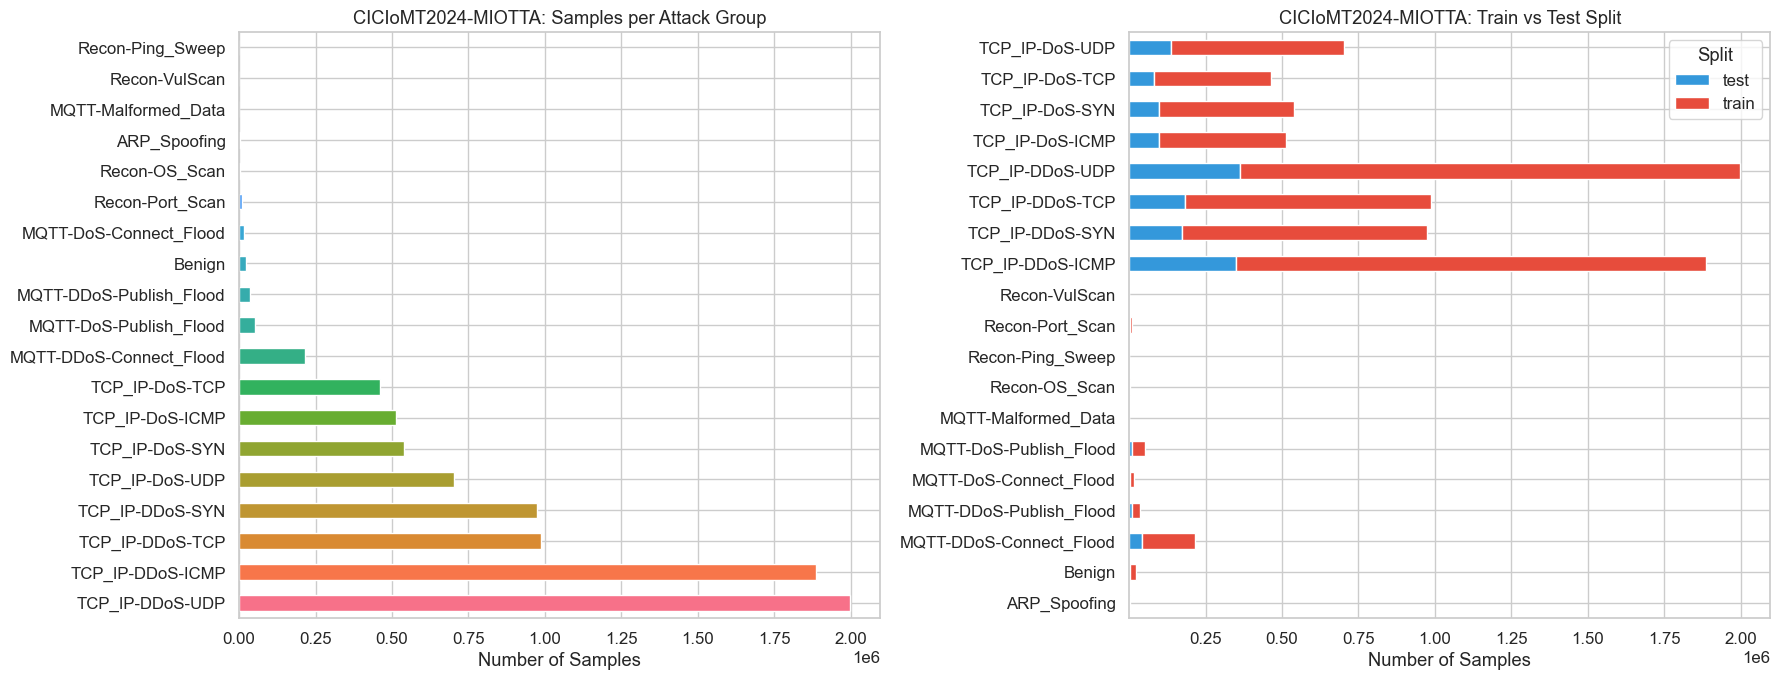

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

group_counts.plot(kind='barh', ax=axes[0], color=sns.color_palette('husl', len(group_counts)))
axes[0].set_title('CICIoMT2024-MIOTTA: Samples per Attack Group')
axes[0].set_xlabel('Number of Samples')
axes[0].set_ylabel('')

split_dist = cic_all.groupby(['attack_group', 'split']).size().unstack(fill_value=0)
split_dist.plot(kind='barh', stacked=True, ax=axes[1], color=['#3498db', '#e74c3c'])
axes[1].set_title('CICIoMT2024-MIOTTA: Train vs Test Split')
axes[1].set_xlabel('Number of Samples')
axes[1].set_ylabel('')
axes[1].legend(title='Split')

plt.tight_layout()
plt.show()

### 4c. Broad Attack Category Mapping

Following the taxonomy from the CICIoMT2024 paper and JITEL2025:

=== CICIoMT2024 — Broad Attack Categories ===

  DDoS                  6,095,188  (72.36%)
  DoS                   2,290,016  (27.18%)
  Benign                   23,133  ( 0.27%)
  Reconnaissance           13,147  ( 0.16%)
  Spoofing                  1,782  ( 0.02%)
  Injection                   689  ( 0.01%)


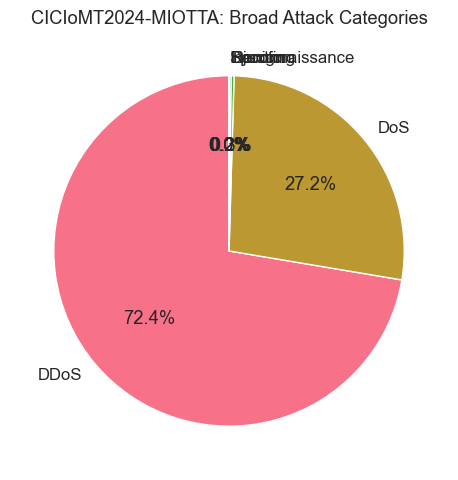

In [10]:
CICIOMT_CATEGORY_MAP = {
    'Benign': 'Benign',
    'ARP_Spoofing': 'Spoofing',
    'MQTT-DDoS-Connect_Flood': 'DDoS',
    'MQTT-DDoS-Publish_Flood': 'DDoS',
    'MQTT-DoS-Connect_Flood': 'DoS',
    'MQTT-DoS-Publish_Flood': 'DoS',
    'MQTT-Malformed_Data': 'Injection',
    'Recon-OS_Scan': 'Reconnaissance',
    'Recon-Ping_Sweep': 'Reconnaissance',
    'Recon-Port_Scan': 'Reconnaissance',
    'Recon-VulScan': 'Reconnaissance',
    'TCP_IP-DDoS-ICMP': 'DDoS',
    'TCP_IP-DDoS-SYN': 'DDoS',
    'TCP_IP-DDoS-TCP': 'DDoS',
    'TCP_IP-DDoS-UDP': 'DDoS',
    'TCP_IP-DoS-ICMP': 'DoS',
    'TCP_IP-DoS-SYN': 'DoS',
    'TCP_IP-DoS-TCP': 'DoS',
    'TCP_IP-DoS-UDP': 'DoS',
}

cic_all['attack_category'] = cic_all['attack_group'].map(CICIOMT_CATEGORY_MAP)

cat_counts = cic_all['attack_category'].value_counts()
print('=== CICIoMT2024 — Broad Attack Categories ===\n')
for cat, cnt in cat_counts.items():
    pct = 100 * cnt / len(cic_all)
    print(f'  {cat:20s} {cnt:>10,}  ({pct:5.2f}%)')

fig, ax = plt.subplots(figsize=(8, 5))
cat_counts.plot(kind='pie', ax=ax, autopct='%1.1f%%', startangle=90)
ax.set_title('CICIoMT2024-MIOTTA: Broad Attack Categories')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

## 5. IoMT-TrafficData-MIOTTA: Exploration

### 5a. Feature Overview

In [11]:
iomt_feature_cols = [c for c in iomt.columns if c not in ['attack_type', 'source_file']]
print(f'Number of numeric features: {len(iomt_feature_cols)}')
print(f'\nData types:')
print(iomt[iomt_feature_cols].dtypes.value_counts())

print('\n=== IoMT-TrafficData-MIOTTA: First 5 Rows ===')
iomt[iomt_feature_cols].head()

Number of numeric features: 73

Data types:
float64    73
Name: count, dtype: int64

=== IoMT-TrafficData-MIOTTA: First 5 Rows ===


,Window,Header_Length,Protocol_Type,TTL,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,ack_flag_number,ece_flag_number,cwr_flag_number,HTTP,HTTPS,DNS,Telnet,SMTP,SSH,IRC,TCP,UDP,DHCP,ARP,ICMP,IGMP,IPV4,LLC,IAT,Tot_size,tcp_analysis_initial_rtt,tcp_connection_fin,tcp_connection_syn,tcp_flags_cwr,tcp_flags_ece,tcp_urgent_pointer,ip_frag_offset,eth_src_not_group,Rate,Srate,Drate,ack_count,syn_count,fin_count,rst_count,Bytes,Min_Length,Max_Length,Avg_Length,Std_Length,Number,Magnite,Radius,Covariance,Var_Ratio,Weight,Orig_Bytes,Resp_Bytes,Orig_Pkts,Resp_Pkts,Fwd_Pkts_Tot,Bwd_Pkts_Tot,Fwd_Data_Pkts_Tot,Bwd_Data_Pkts_Tot,Fwd_Pkts_Per_Sec,Bwd_Pkts_Per_Sec,Flow_Pkts_Per_Sec,Fwd_Header_Size,Bwd_Header_Size,Fwd_Pkts_Payload,Bwd_Pkts_Payload,Flow_Pkts_Payload,Fwd_IAT,Bwd_IAT,Flow_IAT
0,0.0000,1.7600,1.1400,10.8500,0.0000,0.0000,0.0000,0.0200,0.0400,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0400,0.0600,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0052,67.7100,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0408,0.0000,0.0000,0.0000,69.0918,67.2959,67.4184,67.3571,0.0612,1.0204,11.6001,0.0866,0.1837,0.0204,1.0612,57.1531,57.2143,0.9796,0.9796,0.9796,0.9796,0.0000,0.0000,0.0000,0.0000,0.0000,8.8163,8.8163,57.1531,57.2143,1.0204,0.0000,0.0000,0.0000
1,1.0000,4.0800,0.8700,3.8700,0.0000,0.0000,0.0000,0.0600,0.1200,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.1200,0.0300,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0293,68.8500,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.1333,0.0000,0.0000,0.0000,76.5000,66.9889,67.1222,67.0556,0.0667,1.1111,11.5744,0.0943,0.2000,0.0222,1.7778,62.5778,62.5778,1.1000,1.1000,1.1000,1.1000,0.0000,0.0000,0.0000,0.0000,0.0000,13.0667,13.0667,62.5778,62.5778,1.1111,0.0000,0.0000,0.0000
2,2.0000,2.1600,1.9900,12.7900,0.0000,0.0000,0.0000,0.0200,0.0400,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0400,0.1100,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0151,69.0400,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0408,0.0000,0.0000,0.0000,70.4490,68.6531,68.7755,68.7143,0.0612,1.0204,11.7081,0.0866,0.1837,0.0204,1.0612,60.9796,59.2041,1.0204,1.0000,1.0204,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,9.4694,9.3061,60.9796,59.2041,1.0204,0.0000,0.0000,0.0000
3,3.0000,1.3600,0.2900,1.2900,0.0000,0.0000,0.0000,0.0200,0.0400,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0400,0.0100,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0054,66.8700,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0408,0.0000,0.0000,0.0000,68.2347,66.4388,66.5612,66.5000,0.0612,1.0204,11.5264,0.0866,0.1837,0.0204,1.0612,58.7653,58.7653,1.0204,1.0204,1.0204,1.0204,0.0000,0.0000,0.0000,0.0000,0.0000,9.4694,9.4694,58.7653,58.7653,1.0204,0.0000,0.0000,0.0000
4,4.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0051,66.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,66.0000,66.0000,66.0000,66.0000,0.0000,1.0000,11.4891,0.0000,0.0000,0.0000,1.0000,58.0000,58.0000,1.0000,1.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,8.0000,8.0000,58.0000,58.0000,1.0000,0.0000,0.0000,0.0000


In [12]:
print('=== IoMT-TrafficData-MIOTTA: Descriptive Statistics ===')
iomt[iomt_feature_cols].describe().T

=== IoMT-TrafficData-MIOTTA: Descriptive Statistics ===


,count,mean,std,min,25%,50%,75%,max
Window,184241.0000,19318.0839,16846.5514,0.0000,5553.0000,15199.0000,27625.0000,65733.0000
Header_Length,184241.0000,23.9185,11.4483,0.0000,22.0000,26.7200,32.0000,41.8400
Protocol_Type,184241.0000,5.5515,1.2035,0.0000,5.6400,6.0000,6.0000,11.8300
TTL,184241.0000,56.7637,12.6762,0.0000,56.1500,60.1600,62.7200,143.3400
fin_flag_number,19399.0000,0.0561,0.1334,0.0000,0.0000,0.0000,0.0000,1.0000
syn_flag_number,19399.0000,0.1098,0.1654,0.0000,0.0000,0.0000,0.2000,0.6100
rst_flag_number,19399.0000,0.0561,0.1571,0.0000,0.0000,0.0000,0.0000,0.5400
psh_flag_number,19399.0000,0.1981,0.2103,0.0000,0.0000,0.2000,0.3600,1.0000
ack_flag_number,19399.0000,0.5845,0.4005,0.0000,0.0400,0.7600,0.9200,1.0000
ece_flag_number,19399.0000,0.0000,0.0004,0.0000,0.0000,0.0000,0.0000,0.0400


### 5b. Attack Type Distribution

=== IoMT-TrafficData-MIOTTA: Samples per Attack Type ===

  MQTT Malaria                            65,734  (35.68%)
  Net Scan                                32,879  (17.85%)
  IP-Based Normal Capture                 30,323  (16.46%)
  CAM Table Overflow                      23,984  (13.02%)
  Apache Killer                           10,772  ( 5.85%)
  RUDY                                     7,809  ( 4.24%)
  ARP Spoofing 01                          3,783  ( 2.05%)
  ARP Spoofing 02                          3,780  ( 2.05%)
  Slow Loris                               3,778  ( 2.05%)
  Slow Read                                1,399  ( 0.76%)
  TOTAL                                  184,241


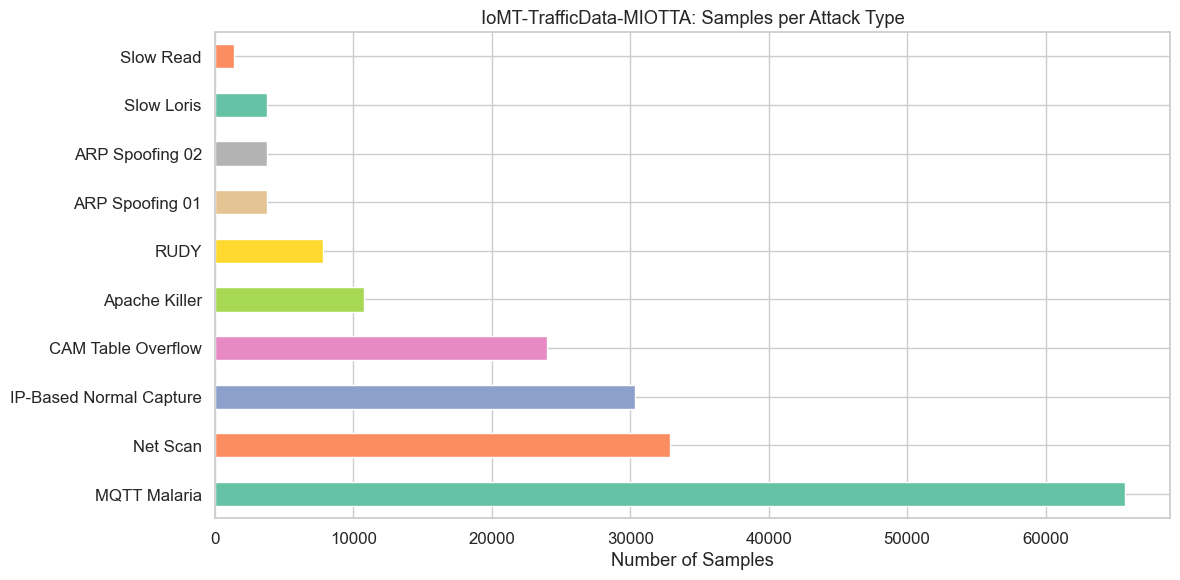

In [13]:
iomt_label_col = 'attack_type'

iomt_counts = iomt[iomt_label_col].value_counts()
print(f'=== IoMT-TrafficData-MIOTTA: Samples per Attack Type ===\n')
for g, c in iomt_counts.items():
    pct = 100 * c / len(iomt)
    print(f'  {g:35s} {c:>10,}  ({pct:5.2f}%)')
print(f'  {"TOTAL":35s} {len(iomt):>10,}')

fig, ax = plt.subplots(figsize=(12, 6))
iomt_counts.plot(kind='barh', ax=ax, color=sns.color_palette('Set2', len(iomt_counts)))
ax.set_title('IoMT-TrafficData-MIOTTA: Samples per Attack Type')
ax.set_xlabel('Number of Samples')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

### 5c. Broad Attack Category Mapping

=== IoMT-TrafficData — Broad Attack Categories ===



  DoS                     113,476  (61.59%)
  Reconnaissance           32,879  (17.85%)
  Benign                   30,323  (16.46%)
  Spoofing                  7,563  ( 4.10%)


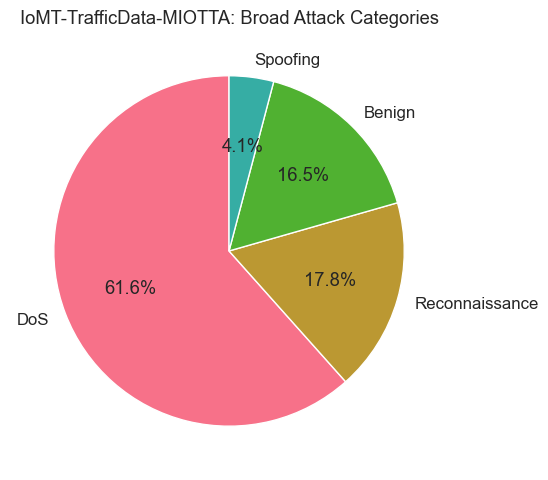

In [14]:
IOMT_CATEGORY_MAP = {
    'IP-Based Normal Capture': 'Benign',
    'ARP Spoofing 01': 'Spoofing',
    'ARP Spoofing 02': 'Spoofing',
    'Apache Killer': 'DoS',
    'CAM Table Overflow': 'DoS',
    'MQTT Malaria': 'DoS',
    'Net Scan': 'Reconnaissance',
    'RUDY': 'DoS',
    'Slow Loris': 'DoS',
    'Slow Read': 'DoS',
}

iomt['attack_category'] = iomt['attack_type'].map(IOMT_CATEGORY_MAP)

iomt_cat_counts = iomt['attack_category'].value_counts()
print('=== IoMT-TrafficData — Broad Attack Categories ===\n')
for cat, cnt in iomt_cat_counts.items():
    pct = 100 * cnt / len(iomt)
    print(f'  {cat:20s} {cnt:>10,}  ({pct:5.2f}%)')

fig, ax = plt.subplots(figsize=(8, 5))
iomt_cat_counts.plot(kind='pie', ax=ax, autopct='%1.1f%%', startangle=90)
ax.set_title('IoMT-TrafficData-MIOTTA: Broad Attack Categories')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

## 6. Feature Comparison Between Datasets

Since both datasets were processed with the same MIOTTA-NPT tool and configuration, they should share identical features.

In [15]:
cic_features = set(feature_cols)
iomt_features = set(iomt_feature_cols)

common = cic_features & iomt_features
only_cic = cic_features - iomt_features
only_iomt = iomt_features - cic_features

print(f'Common features:          {len(common)}')
print(f'Only in CICIoMT2024:      {len(only_cic)}  {only_cic if only_cic else "(none)"}')
print(f'Only in IoMT-TrafficData: {len(only_iomt)}  {only_iomt if only_iomt else "(none)"}')
print(f'\nFeatures are identical: {cic_features == iomt_features}')

Common features:          73
Only in CICIoMT2024:      0  (none)
Only in IoMT-TrafficData: 0  (none)

Features are identical: True


In [16]:
shared_features = sorted(common - {'Window'})

comparison = pd.DataFrame({
    'CICIoMT2024_mean': cic_all[shared_features].mean(),
    'CICIoMT2024_std': cic_all[shared_features].std(),
    'IoMT-TrafficData_mean': iomt[shared_features].mean(),
    'IoMT-TrafficData_std': iomt[shared_features].std(),
})
comparison['mean_diff_ratio'] = np.where(
    comparison['CICIoMT2024_mean'] != 0,
    (comparison['IoMT-TrafficData_mean'] - comparison['CICIoMT2024_mean']) / comparison['CICIoMT2024_mean'].abs(),
    np.where(comparison['IoMT-TrafficData_mean'] != 0, np.inf, 0)
)

print('=== Feature-wise Comparison: CICIoMT2024 vs IoMT-TrafficData (MIOTTA) ===')
comparison

=== Feature-wise Comparison: CICIoMT2024 vs IoMT-TrafficData (MIOTTA) ===


,CICIoMT2024_mean,CICIoMT2024_std,IoMT-TrafficData_mean,IoMT-TrafficData_std,mean_diff_ratio
ARP,0.0000,0.0000,0.0000,0.0000,0.0000
Avg_Length,64.0416,40.3394,151.3770,196.0109,1.3637
Bwd_Data_Pkts_Tot,0.0000,0.0000,0.0000,0.0000,0.0000
Bwd_Header_Size,19.3371,76.3382,100.1665,95.2526,4.1800
Bwd_IAT,0.0000,0.0000,0.0000,0.0000,5.3750
Bwd_Pkts_Payload,102.3160,2329.7677,767.3117,2677.2396,6.4994
Bwd_Pkts_Per_Sec,28.2839,8679.1027,8095.8329,149932.2879,285.2343
Bwd_Pkts_Tot,1.0721,1.8694,2.7152,2.3021,1.5326
Bytes,121.6740,2400.9983,874.5313,2757.5342,6.1875
Covariance,309.2738,6048.6192,262377.5251,1001790.7019,847.3664


### 6b. Scale Comparison Visualization

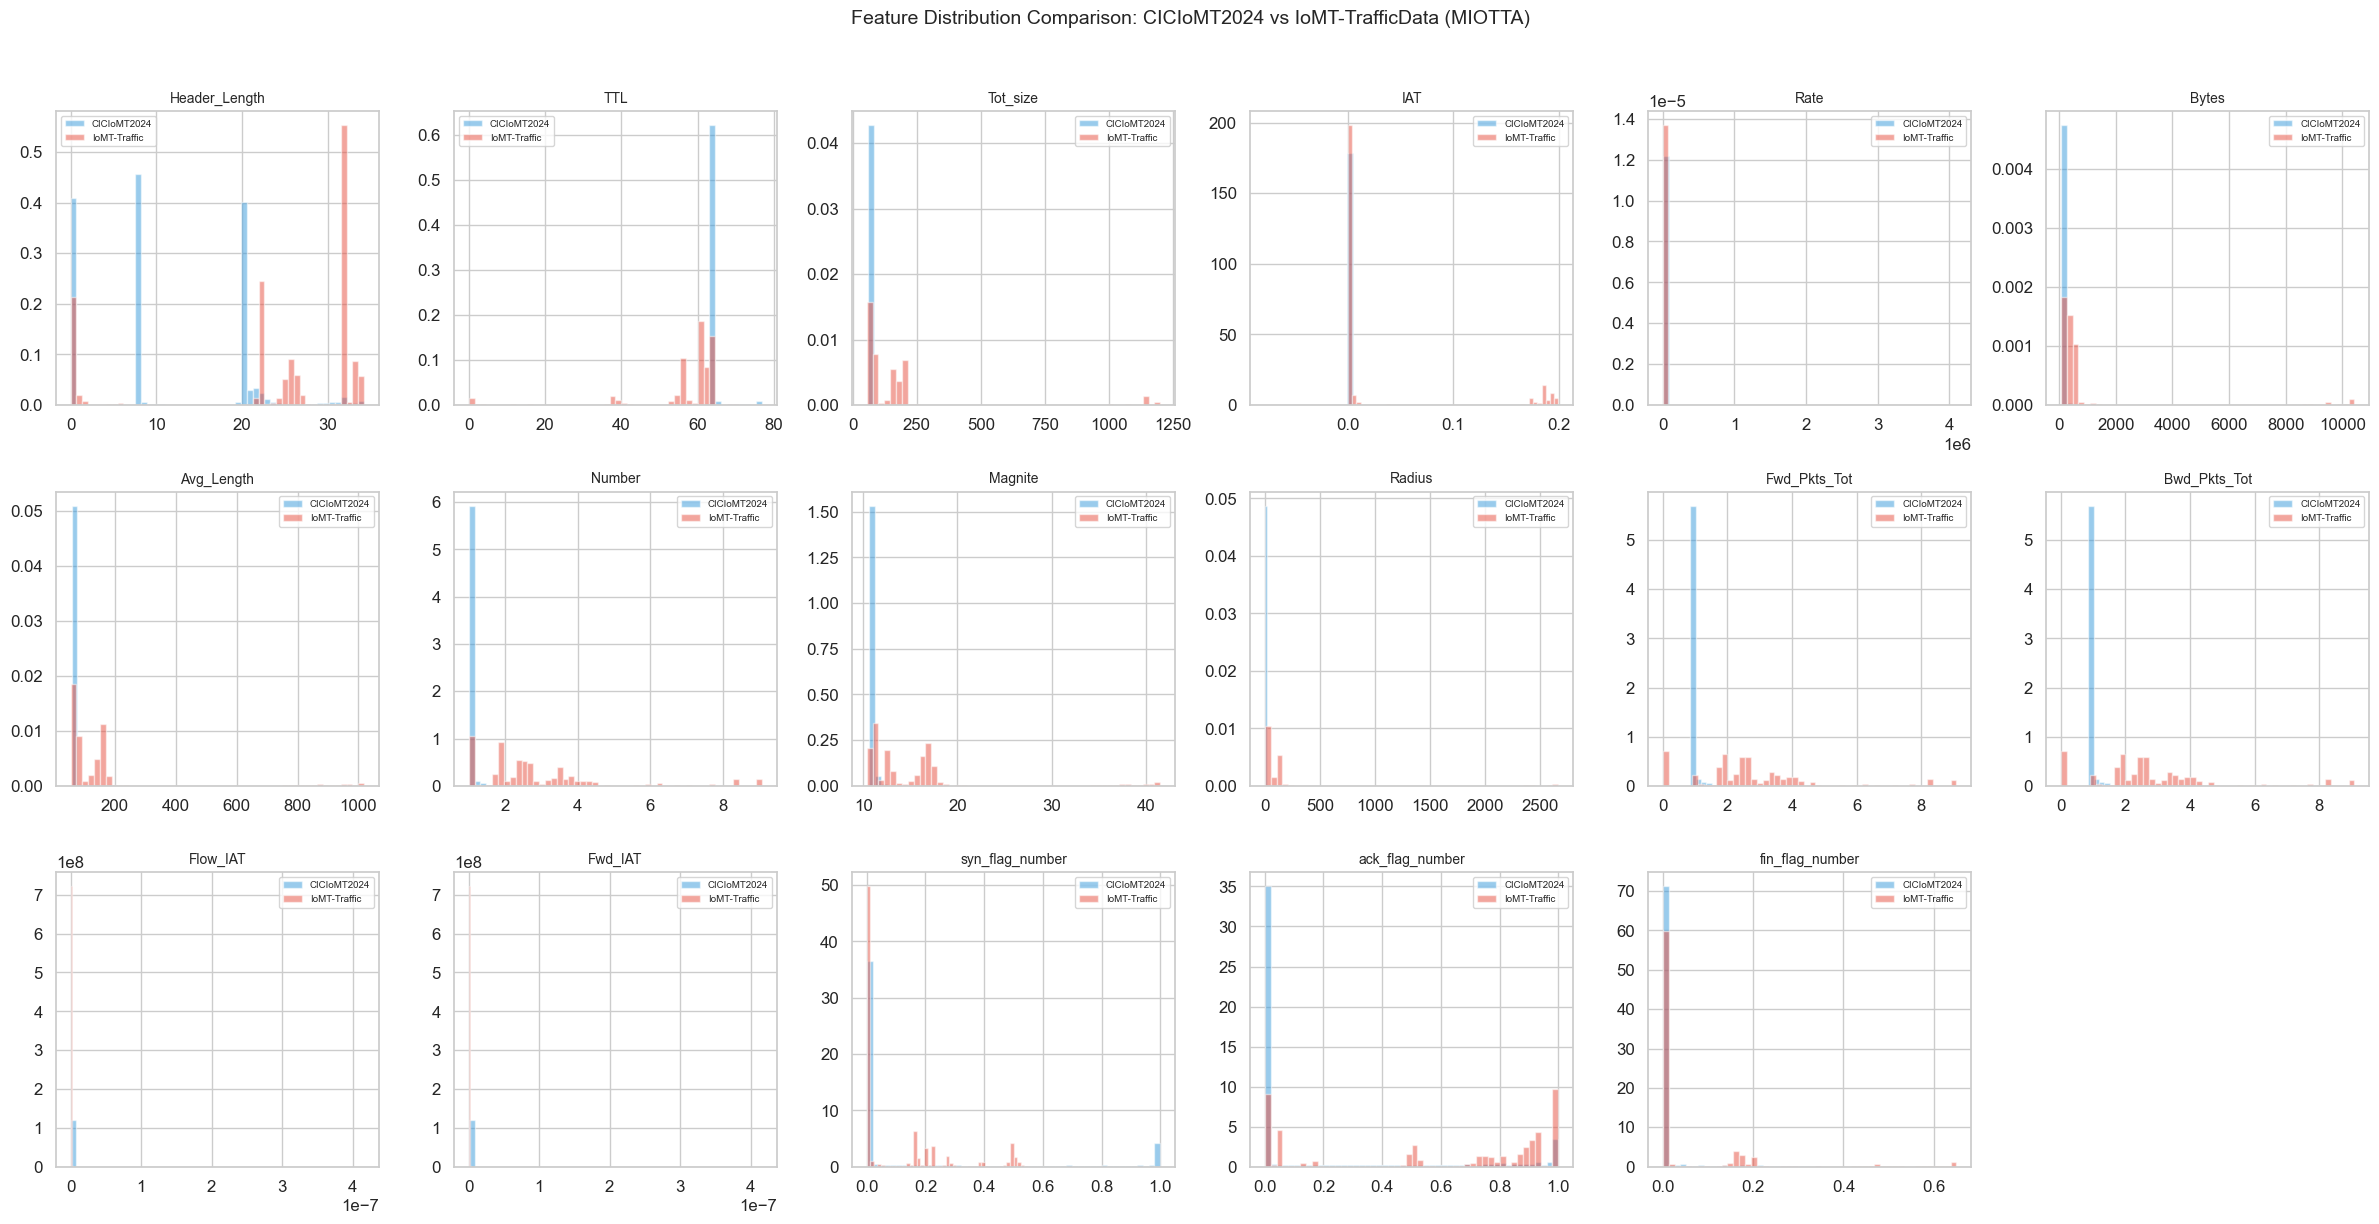

In [17]:
key_features = [
    'Header_Length', 'TTL', 'Tot_size', 'IAT', 'Rate',
    'Bytes', 'Avg_Length', 'Number', 'Magnite', 'Radius',
    'Fwd_Pkts_Tot', 'Bwd_Pkts_Tot', 'Flow_IAT', 'Fwd_IAT',
    'syn_flag_number', 'ack_flag_number', 'fin_flag_number'
]
key_features = [f for f in key_features if f in shared_features]

fig, axes = plt.subplots(3, 6, figsize=(24, 12))
axes = axes.flatten()

for i, feat in enumerate(key_features[:18]):
    ax = axes[i]
    cic_vals = cic_all[feat].dropna()
    iomt_vals = iomt[feat].dropna()
    
    q99_cic = cic_vals.quantile(0.99) if len(cic_vals) > 0 else 0
    q99_iomt = iomt_vals.quantile(0.99) if len(iomt_vals) > 0 else 0
    upper = max(q99_cic, q99_iomt)
    
    if upper > 0:
        cic_clipped = cic_vals.clip(upper=upper)
        iomt_clipped = iomt_vals.clip(upper=upper)
    else:
        cic_clipped = cic_vals
        iomt_clipped = iomt_vals
    
    ax.hist(cic_clipped, bins=50, alpha=0.5, label='CICIoMT2024', density=True, color='#3498db')
    ax.hist(iomt_clipped, bins=50, alpha=0.5, label='IoMT-Traffic', density=True, color='#e74c3c')
    ax.set_title(feat, fontsize=10)
    ax.legend(fontsize=7)

for j in range(len(key_features), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Feature Distribution Comparison: CICIoMT2024 vs IoMT-TrafficData (MIOTTA)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 7. Missing Values & Data Quality

In [18]:
print('=== CICIoMT2024-MIOTTA: Missing Values ===')
cic_missing = cic_all[feature_cols].isnull().sum()
cic_missing_pct = 100 * cic_missing / len(cic_all)
cic_miss_df = pd.DataFrame({'missing_count': cic_missing, 'missing_pct': cic_missing_pct})
cic_miss_df = cic_miss_df[cic_miss_df['missing_count'] > 0].sort_values('missing_pct', ascending=False)

if len(cic_miss_df) > 0:
    display(cic_miss_df)
    print(f'\nNote: TCP flag features (fin/syn/rst/psh/ack/ece/cwr_flag_number, tcp_flags_ece)')
    print(f'are NaN for windows without TCP traffic (~60% of rows).')
    print(f'This is expected behavior from the MIOTTA-NPT tool.')
else:
    print('No missing values found!')

print(f'\nInfinite values per feature:')
cic_inf = cic_all[feature_cols].apply(lambda x: np.isinf(x.astype(float)).sum() if x.dtype in ['float64', 'int64'] else 0)
cic_inf_nonzero = cic_inf[cic_inf > 0]
if len(cic_inf_nonzero) > 0:
    print(cic_inf_nonzero)
else:
    print('No infinite values found!')

=== CICIoMT2024-MIOTTA: Missing Values ===


,missing_count,missing_pct
fin_flag_number,8295000,98.4692
syn_flag_number,8295000,98.4692
rst_flag_number,8295000,98.4692
psh_flag_number,8295000,98.4692
ack_flag_number,8295000,98.4692
ece_flag_number,8295000,98.4692
cwr_flag_number,8295000,98.4692
tcp_flags_ece,8295000,98.4692
IAT,1,0.0000



Infinite values per feature:


No infinite values found!


In [19]:
print('=== IoMT-TrafficData-MIOTTA: Missing Values ===')
iomt_missing = iomt[iomt_feature_cols].isnull().sum()
iomt_missing_pct = 100 * iomt_missing / len(iomt)
iomt_miss_df = pd.DataFrame({'missing_count': iomt_missing, 'missing_pct': iomt_missing_pct})
iomt_miss_df = iomt_miss_df[iomt_miss_df['missing_count'] > 0].sort_values('missing_pct', ascending=False)

if len(iomt_miss_df) > 0:
    display(iomt_miss_df)
else:
    print('No missing values found!')

print(f'\nInfinite values per feature:')
iomt_inf = iomt[iomt_feature_cols].apply(lambda x: np.isinf(x.astype(float)).sum() if x.dtype in ['float64', 'int64'] else 0)
iomt_inf_nonzero = iomt_inf[iomt_inf > 0]
if len(iomt_inf_nonzero) > 0:
    print(iomt_inf_nonzero)
else:
    print('No infinite values found!')

=== IoMT-TrafficData-MIOTTA: Missing Values ===


,missing_count,missing_pct
fin_flag_number,164842,89.4709
syn_flag_number,164842,89.4709
rst_flag_number,164842,89.4709
psh_flag_number,164842,89.4709
ack_flag_number,164842,89.4709
ece_flag_number,164842,89.4709
cwr_flag_number,164842,89.4709
tcp_flags_ece,164842,89.4709



Infinite values per feature:
No infinite values found!


In [20]:
print('=== CICIoMT2024-MIOTTA: Constant Features (zero variance) ===')
cic_std = cic_all[feature_cols].std()
cic_constant = cic_std[cic_std == 0].index.tolist()
print(f'Constant features: {cic_constant if cic_constant else "None"}')

print('\n=== IoMT-TrafficData-MIOTTA: Constant Features ===')
iomt_std = iomt[iomt_feature_cols].std()
iomt_constant = iomt_std[iomt_std == 0].index.tolist()
print(f'Constant features: {iomt_constant if iomt_constant else "None"}')

print('\n=== Near-Constant Features (>99.9% same value) ===')
for name, df_, cols in [('CICIoMT2024', cic_all, feature_cols), ('IoMT-TrafficData', iomt, iomt_feature_cols)]:
    near_const = []
    for c in cols:
        if df_[c].dtype in ['float64', 'int64', 'float32', 'int32']:
            mode_pct = df_[c].value_counts(normalize=True).iloc[0] if len(df_[c].value_counts()) > 0 else 0
            if mode_pct > 0.999:
                near_const.append((c, f'{mode_pct:.4%}'))
    if near_const:
        print(f'  {name}: {near_const}')
    else:
        print(f'  {name}: None')

=== CICIoMT2024-MIOTTA: Constant Features (zero variance) ===


Constant features: ['DHCP', 'ARP', 'IPV4', 'LLC', 'eth_src_not_group', 'Drate', 'Fwd_Data_Pkts_Tot', 'Bwd_Data_Pkts_Tot']

=== IoMT-TrafficData-MIOTTA: Constant Features ===
Constant features: ['DHCP', 'ARP', 'ICMP', 'IGMP', 'IPV4', 'LLC', 'ip_frag_offset', 'Drate', 'Fwd_Data_Pkts_Tot', 'Bwd_Data_Pkts_Tot']

=== Near-Constant Features (>99.9% same value) ===


  CICIoMT2024: [('cwr_flag_number', '99.9085%'), ('Telnet', '99.9382%'), ('SMTP', '99.9385%'), ('SSH', '99.9375%'), ('DHCP', '100.0000%'), ('ARP', '100.0000%'), ('IGMP', '100.0000%'), ('IPV4', '100.0000%'), ('LLC', '100.0000%'), ('tcp_flags_cwr', '99.9929%'), ('tcp_urgent_pointer', '99.9988%'), ('ip_frag_offset', '99.9992%'), ('eth_src_not_group', '100.0000%'), ('Rate', '99.9986%'), ('Srate', '99.9986%'), ('Drate', '100.0000%'), ('Fwd_Data_Pkts_Tot', '100.0000%'), ('Bwd_Data_Pkts_Tot', '100.0000%'), ('Fwd_Pkts_Per_Sec', '99.9986%'), ('Bwd_Pkts_Per_Sec', '99.9986%'), ('Flow_Pkts_Per_Sec', '99.9986%'), ('Fwd_IAT', '99.9986%'), ('Bwd_IAT', '99.9986%'), ('Flow_IAT', '99.9986%')]
  IoMT-TrafficData: [('ece_flag_number', '99.9845%'), ('cwr_flag_number', '99.9845%'), ('Telnet', '99.9837%'), ('SMTP', '99.9843%'), ('IRC', '99.9853%'), ('DHCP', '100.0000%'), ('ARP', '100.0000%'), ('ICMP', '100.0000%'), ('IGMP', '100.0000%'), ('IPV4', '100.0000%'), ('LLC', '100.0000%'), ('tcp_flags_cwr', '99.9571

## 8. Feature Distributions & Correlations

### 8a. Correlation Matrices

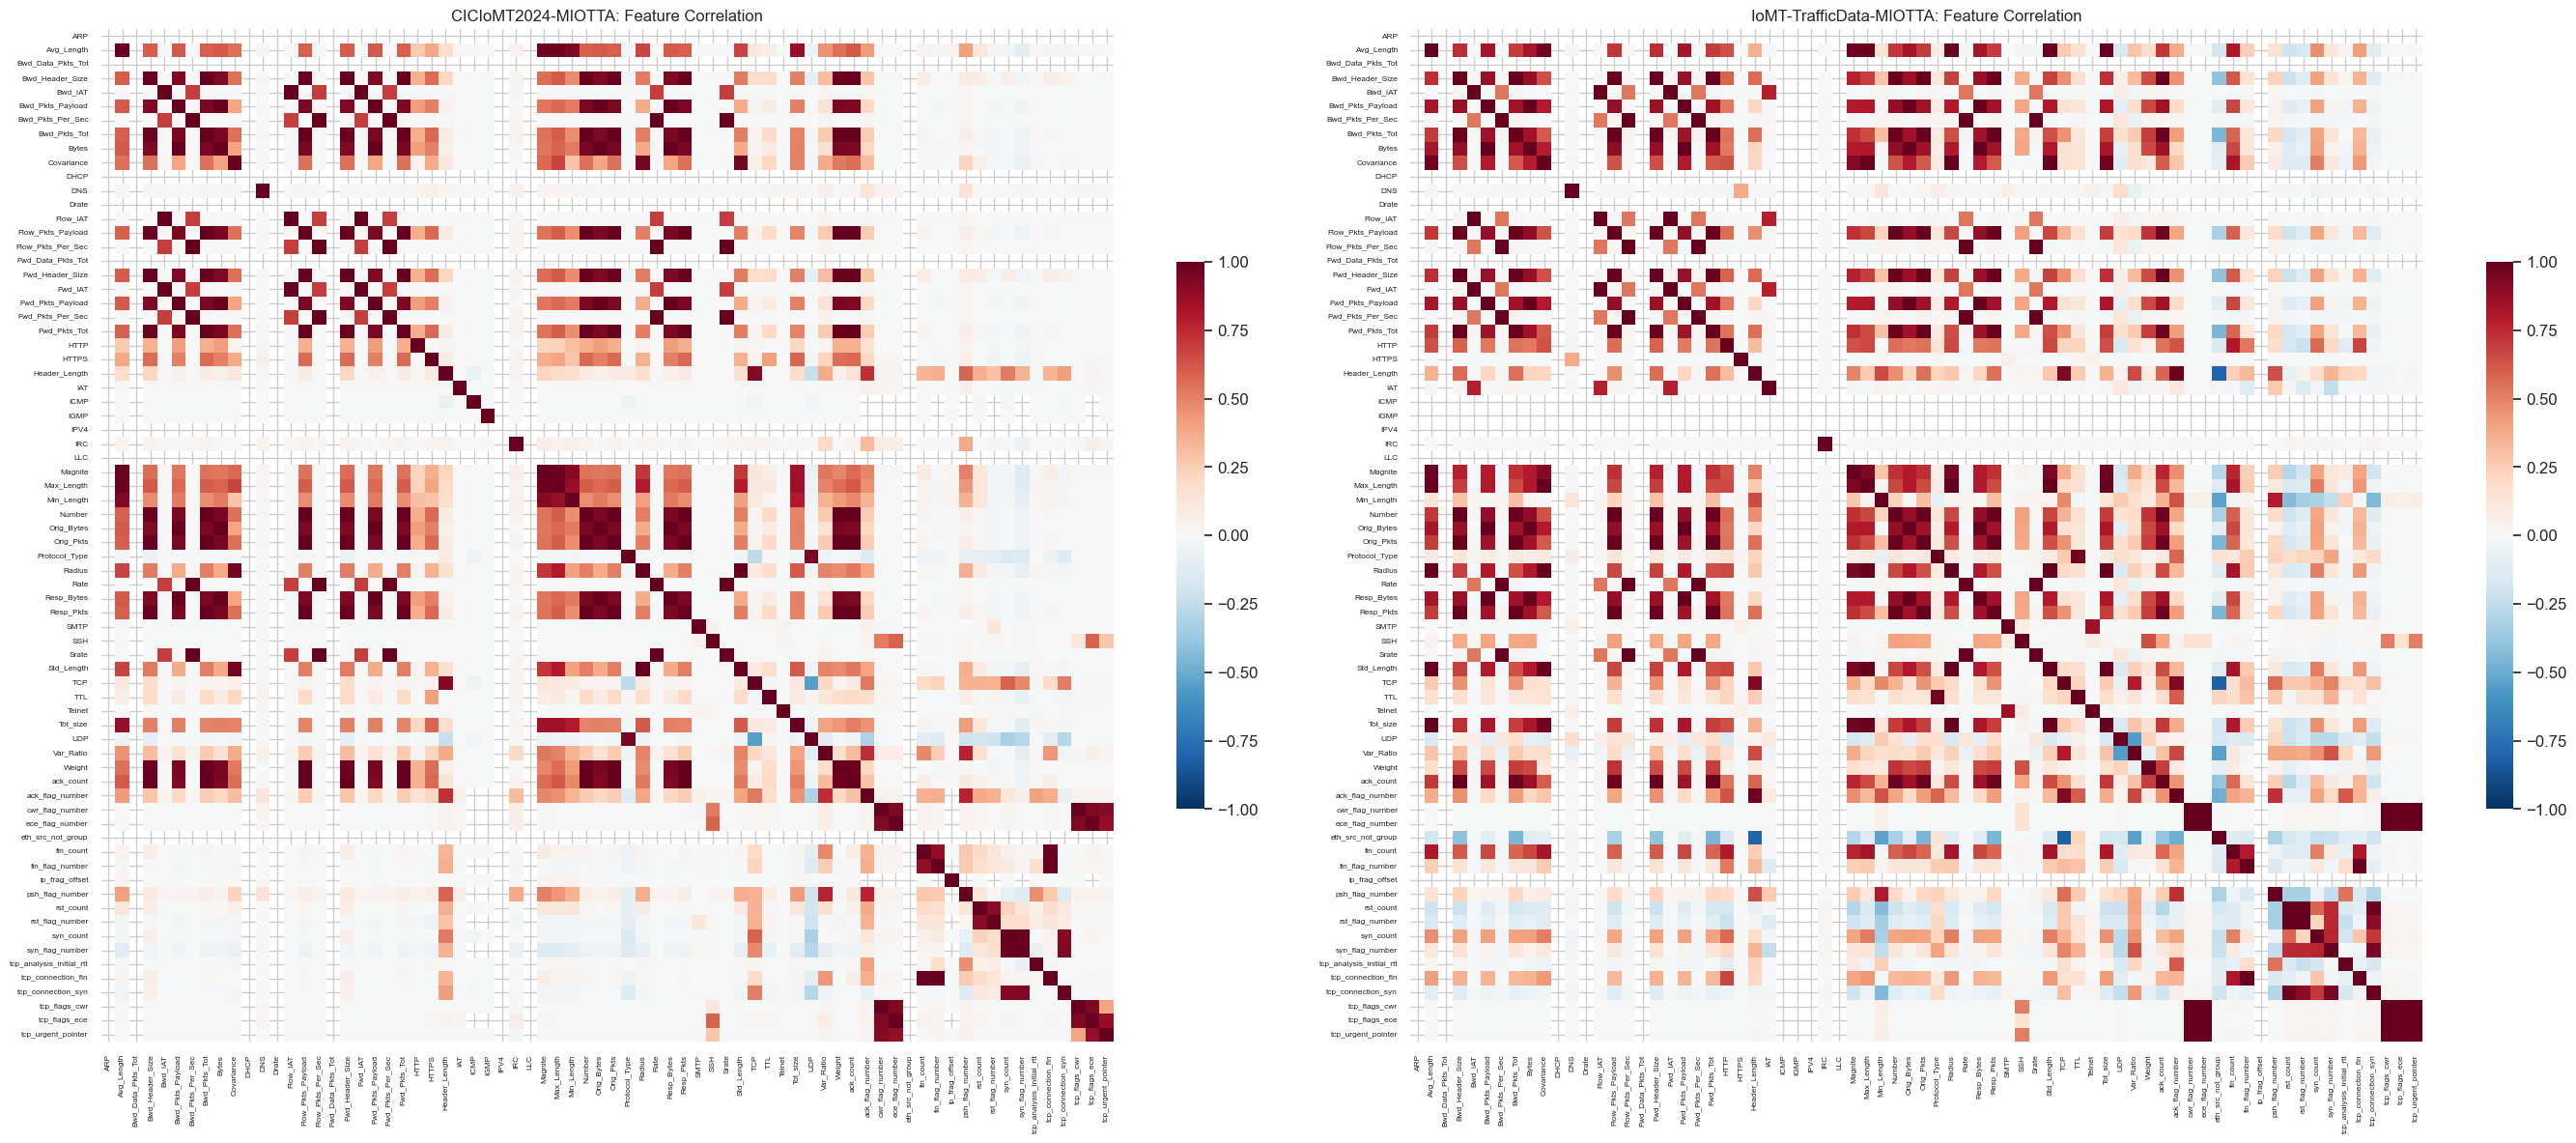

In [21]:
numeric_features = [c for c in shared_features if c != 'Window']

fig, axes = plt.subplots(1, 2, figsize=(28, 12))

cic_corr = cic_all[numeric_features].corr()
sns.heatmap(cic_corr, ax=axes[0], cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            xticklabels=True, yticklabels=True, square=True,
            cbar_kws={'shrink': 0.5})
axes[0].set_title('CICIoMT2024-MIOTTA: Feature Correlation', fontsize=12)
axes[0].tick_params(axis='both', labelsize=6)

iomt_corr = iomt[numeric_features].corr()
sns.heatmap(iomt_corr, ax=axes[1], cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            xticklabels=True, yticklabels=True, square=True,
            cbar_kws={'shrink': 0.5})
axes[1].set_title('IoMT-TrafficData-MIOTTA: Feature Correlation', fontsize=12)
axes[1].tick_params(axis='both', labelsize=6)

plt.tight_layout()
plt.show()

### 8b. Highly Correlated Feature Pairs

In [22]:
def get_high_correlations(corr_matrix, threshold=0.95):
    """Extract feature pairs with correlation above threshold."""
    pairs = []
    cols = corr_matrix.columns
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            if abs(corr_matrix.iloc[i, j]) >= threshold:
                pairs.append((cols[i], cols[j], corr_matrix.iloc[i, j]))
    return pd.DataFrame(pairs, columns=['Feature_1', 'Feature_2', 'Correlation']).sort_values('Correlation', key=abs, ascending=False)

print('=== CICIoMT2024 — Highly Correlated Pairs (|r| >= 0.95) ===')
cic_high_corr = get_high_correlations(cic_corr, 0.95)
display(cic_high_corr)

print('\n=== IoMT-TrafficData — Highly Correlated Pairs (|r| >= 0.95) ===')
iomt_high_corr = get_high_correlations(iomt_corr, 0.95)
display(iomt_high_corr)

=== CICIoMT2024 — Highly Correlated Pairs (|r| >= 0.95) ===


,Feature_1,Feature_2,Correlation
34,Flow_IAT,Fwd_IAT,1.0000
53,Fwd_Pkts_Per_Sec,Rate,1.0000
37,Flow_Pkts_Payload,Number,1.0000
42,Flow_Pkts_Per_Sec,Fwd_Pkts_Per_Sec,1.0000
43,Flow_Pkts_Per_Sec,Rate,1.0000
26,Bwd_Pkts_Tot,Resp_Pkts,1.0000
44,Flow_Pkts_Per_Sec,Srate,1.0000
51,Fwd_Pkts_Payload,Orig_Bytes,1.0000
20,Bwd_Pkts_Per_Sec,Srate,1.0000
19,Bwd_Pkts_Per_Sec,Rate,1.0000



=== IoMT-TrafficData — Highly Correlated Pairs (|r| >= 0.95) ===


,Feature_1,Feature_2,Correlation
46,Flow_Pkts_Per_Sec,Rate,1.0000
78,cwr_flag_number,ece_flag_number,1.0000
29,Bwd_Pkts_Tot,Resp_Pkts,1.0000
41,Flow_Pkts_Payload,Number,1.0000
47,Flow_Pkts_Per_Sec,Srate,1.0000
53,Fwd_Pkts_Payload,Orig_Bytes,1.0000
58,Fwd_Pkts_Tot,Orig_Pkts,1.0000
73,Radius,Std_Length,1.0000
75,Rate,Srate,1.0000
79,cwr_flag_number,tcp_flags_cwr,1.0000


### 8c. Key Feature Distributions by Attack Category

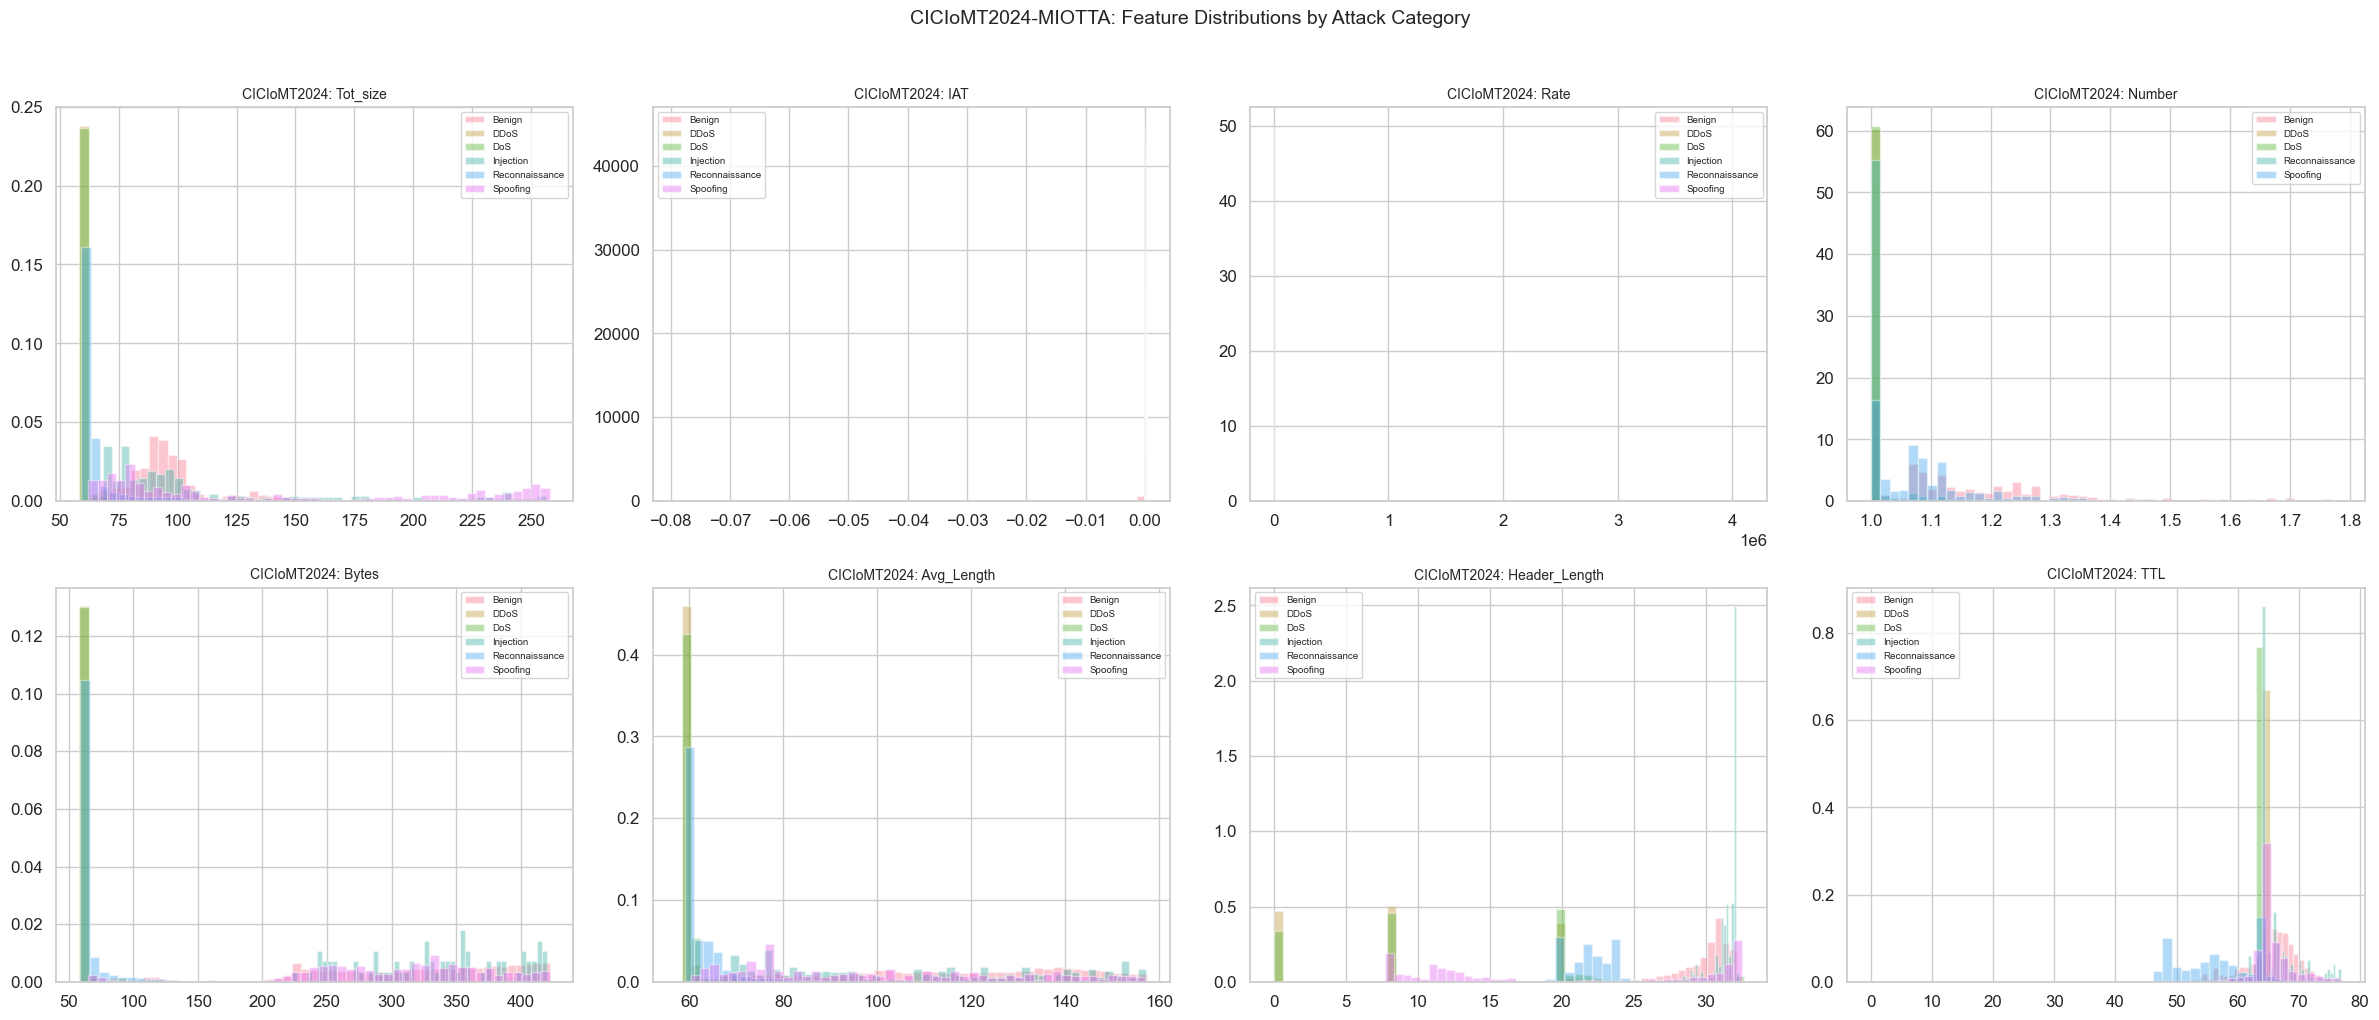

In [23]:
plot_features = ['Tot_size', 'IAT', 'Rate', 'Number', 'Bytes', 'Avg_Length', 'Header_Length', 'TTL']
plot_features = [f for f in plot_features if f in shared_features]

fig, axes = plt.subplots(2, 4, figsize=(24, 10))
axes = axes.flatten()

for i, feat in enumerate(plot_features):
    ax = axes[i]
    data = cic_all[[feat, 'attack_category']].dropna()
    q99 = data[feat].quantile(0.99)
    data_clipped = data[data[feat] <= q99] if q99 > 0 else data
    
    for cat in sorted(data_clipped['attack_category'].unique()):
        subset = data_clipped[data_clipped['attack_category'] == cat][feat]
        ax.hist(subset, bins=50, alpha=0.4, label=cat, density=True)
    ax.set_title(f'CICIoMT2024: {feat}', fontsize=10)
    ax.legend(fontsize=7)

plt.suptitle('CICIoMT2024-MIOTTA: Feature Distributions by Attack Category', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

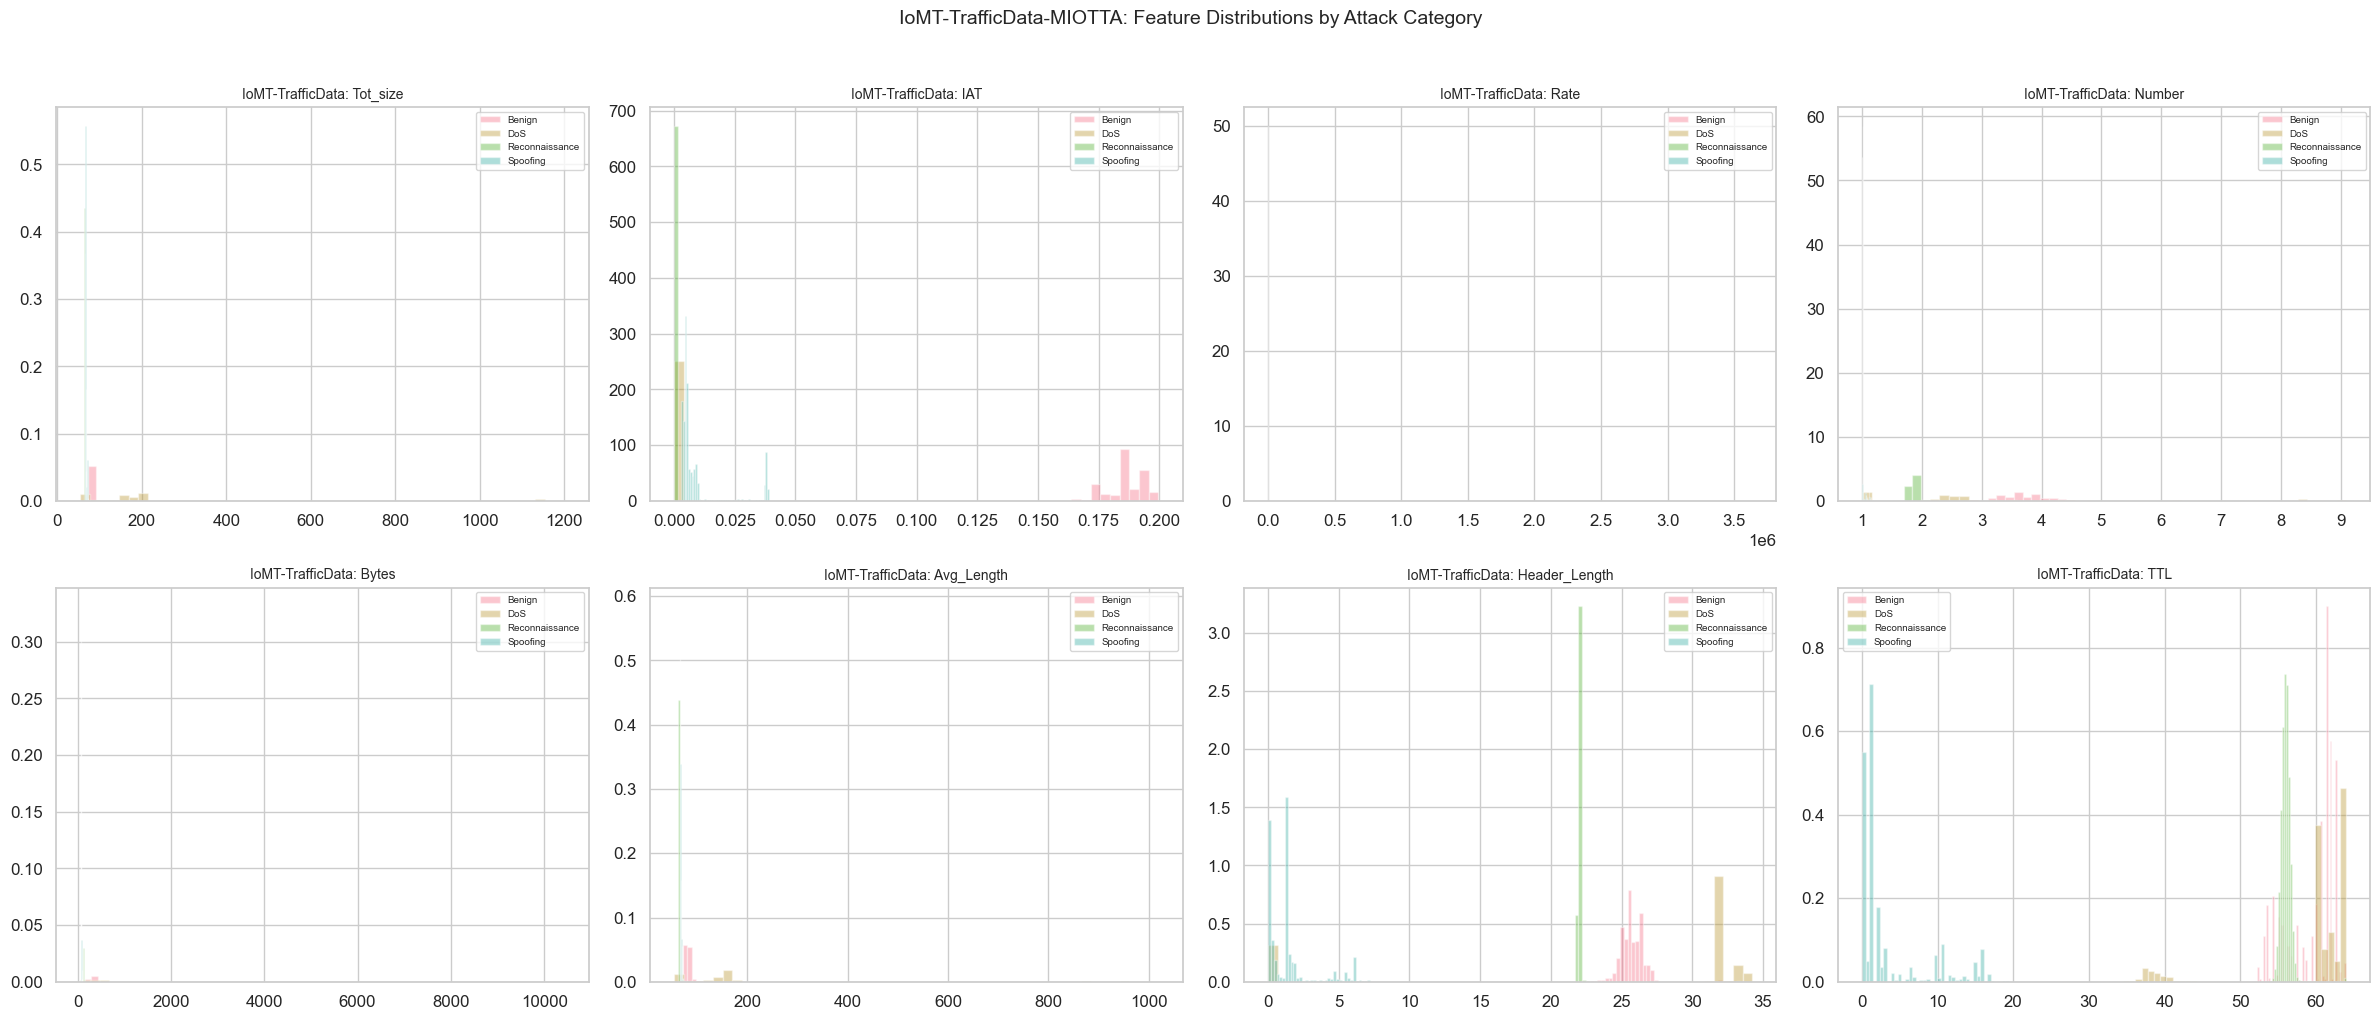

In [24]:
fig, axes = plt.subplots(2, 4, figsize=(24, 10))
axes = axes.flatten()

for i, feat in enumerate(plot_features):
    ax = axes[i]
    data = iomt[[feat, 'attack_category']].dropna()
    q99 = data[feat].quantile(0.99)
    data_clipped = data[data[feat] <= q99] if q99 > 0 else data
    
    for cat in sorted(data_clipped['attack_category'].unique()):
        subset = data_clipped[data_clipped['attack_category'] == cat][feat]
        ax.hist(subset, bins=50, alpha=0.4, label=cat, density=True)
    ax.set_title(f'IoMT-TrafficData: {feat}', fontsize=10)
    ax.legend(fontsize=7)

plt.suptitle('IoMT-TrafficData-MIOTTA: Feature Distributions by Attack Category', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### 8d. Box Plots for Key Features by Attack Category

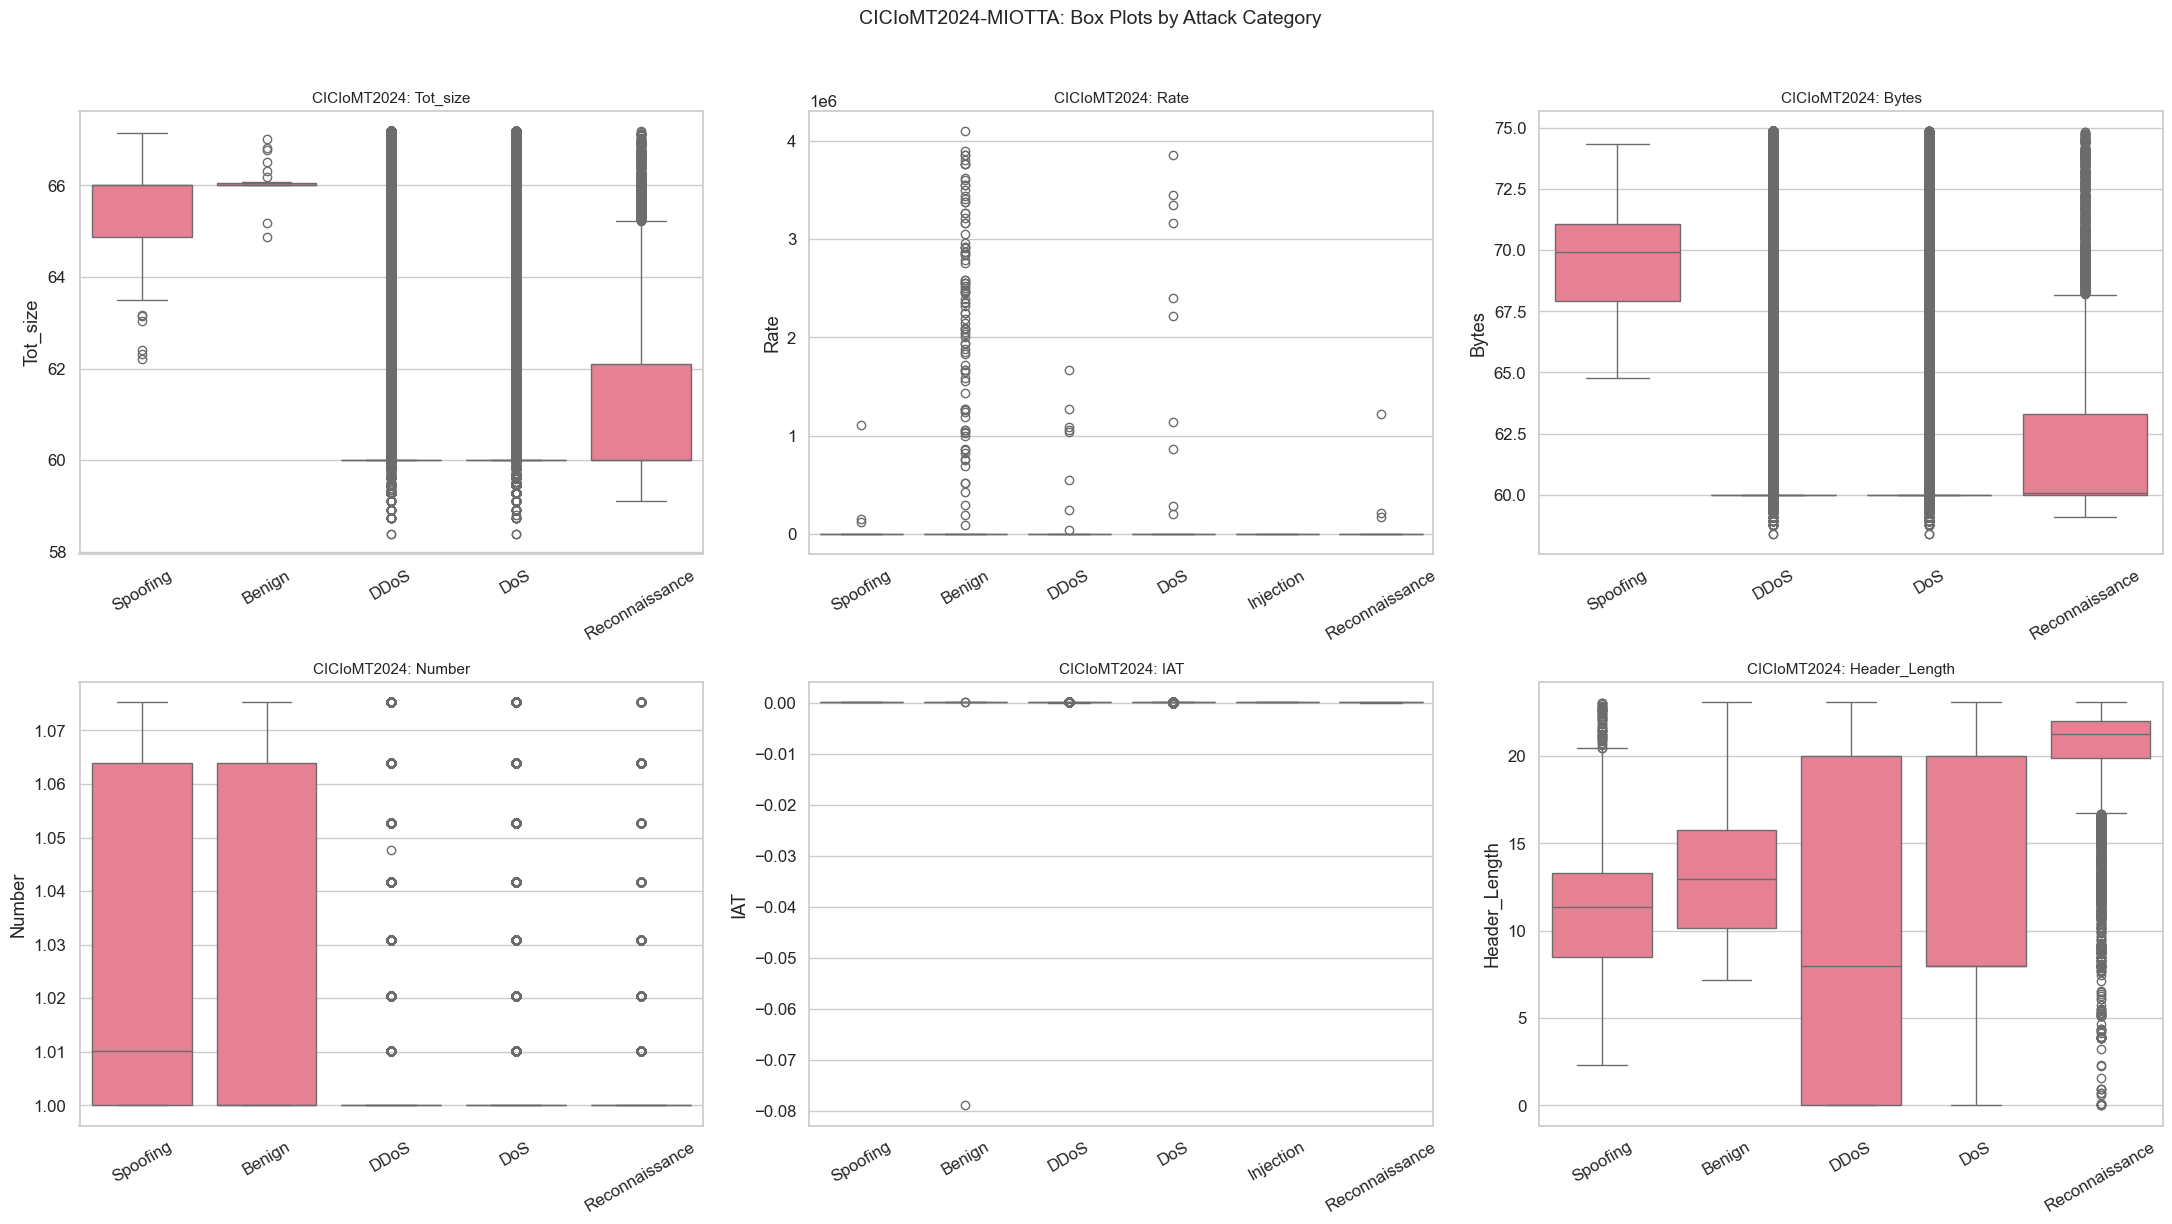

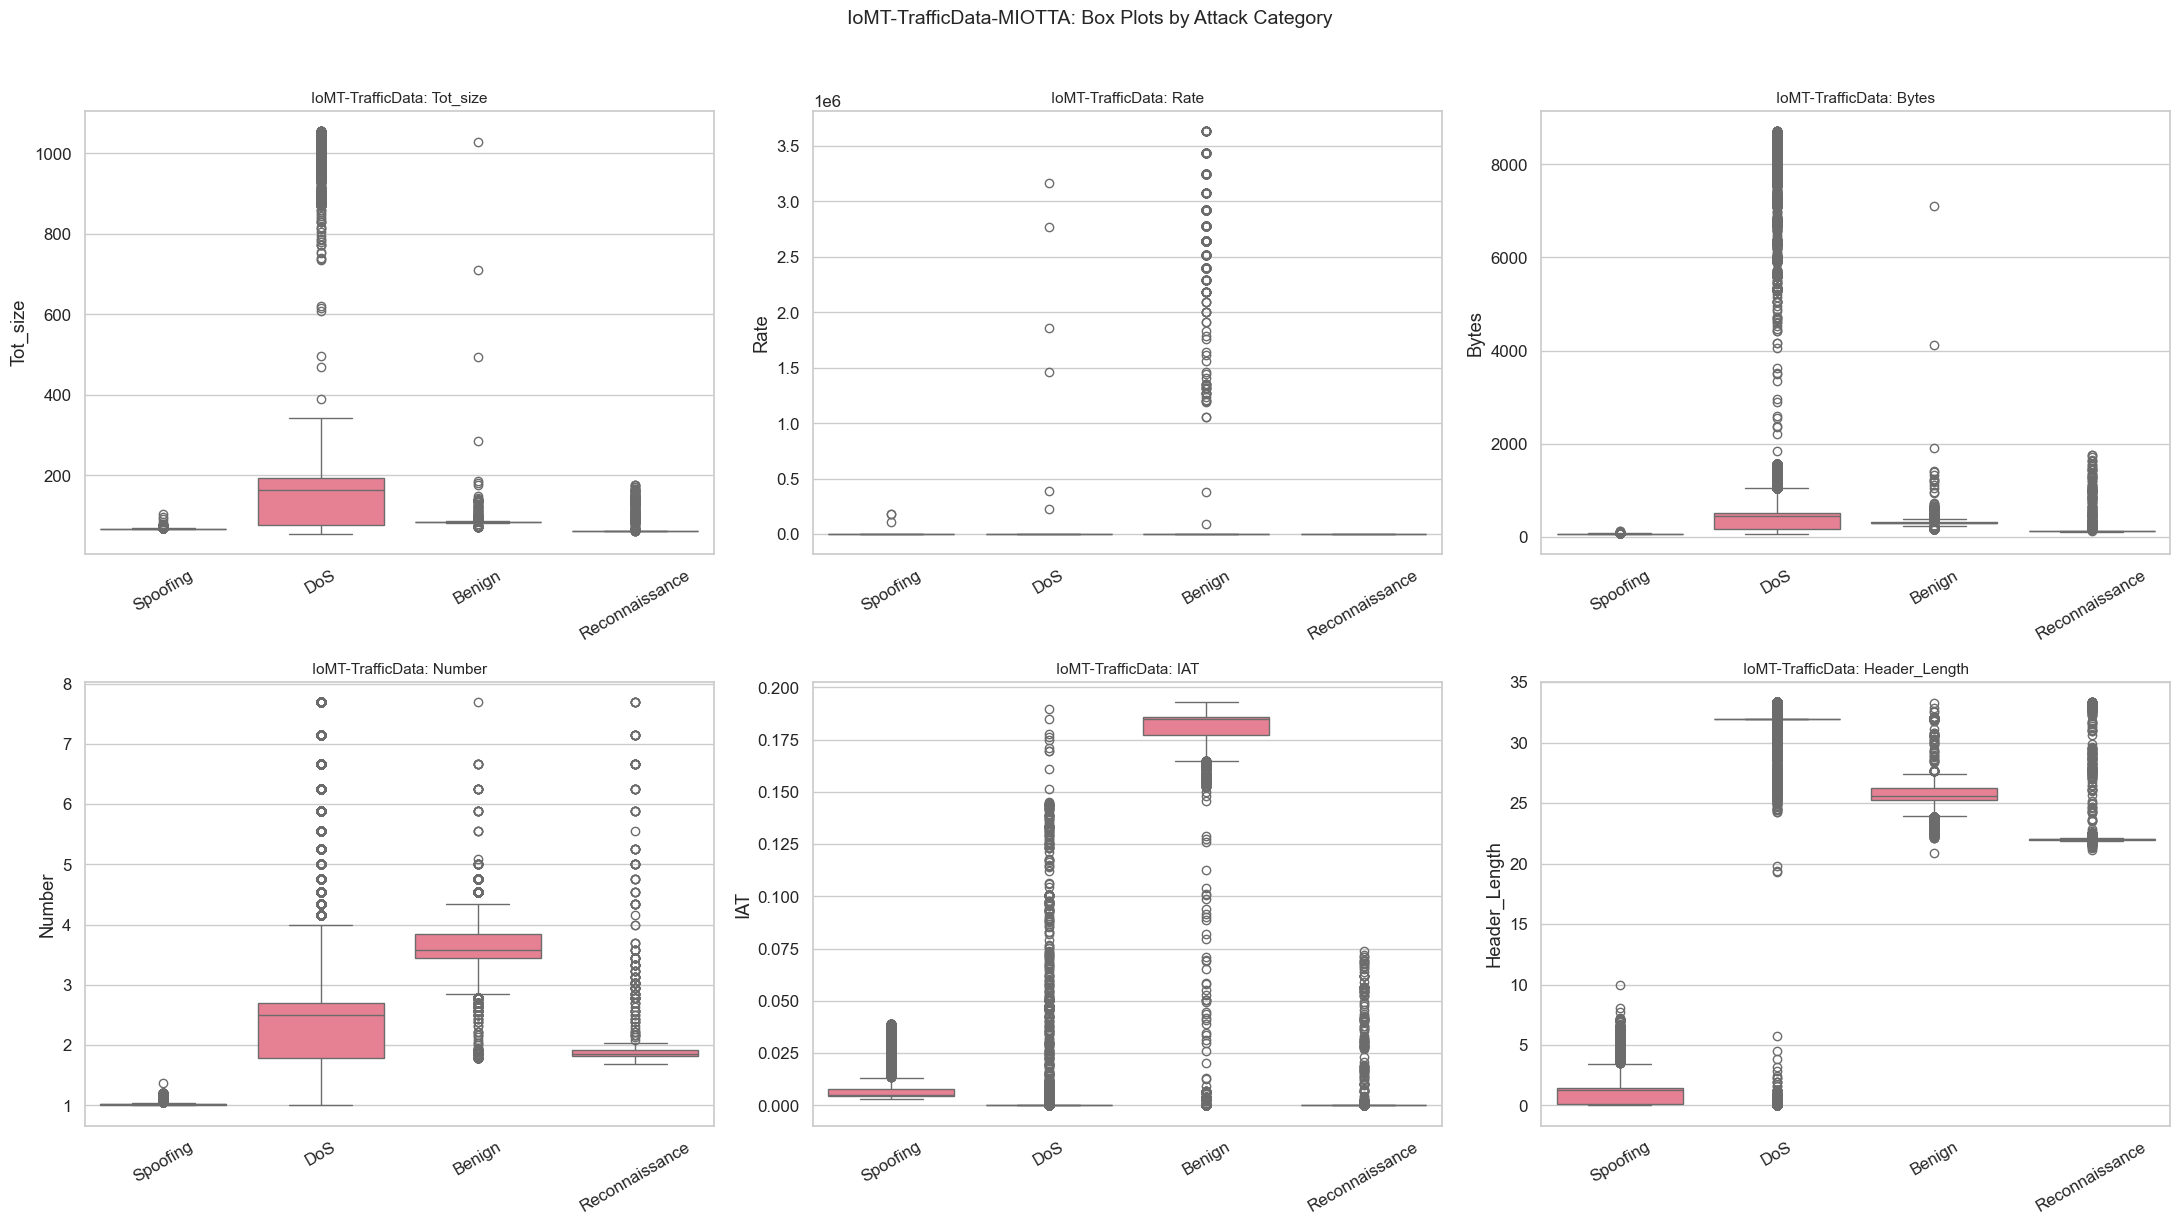

In [25]:
box_features = ['Tot_size', 'Rate', 'Bytes', 'Number', 'IAT', 'Header_Length']
box_features = [f for f in box_features if f in shared_features]

fig, axes = plt.subplots(2, 3, figsize=(22, 12))
axes = axes.flatten()

for i, feat in enumerate(box_features):
    ax = axes[i]
    data = cic_all[[feat, 'attack_category']].dropna()
    q95 = data[feat].quantile(0.95)
    data_clipped = data[data[feat] <= q95] if q95 > 0 else data
    
    sns.boxplot(data=data_clipped, x='attack_category', y=feat, ax=ax)
    ax.set_title(f'CICIoMT2024: {feat}', fontsize=11)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('CICIoMT2024-MIOTTA: Box Plots by Attack Category', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(22, 12))
axes = axes.flatten()

for i, feat in enumerate(box_features):
    ax = axes[i]
    data = iomt[[feat, 'attack_category']].dropna()
    q95 = data[feat].quantile(0.95)
    data_clipped = data[data[feat] <= q95] if q95 > 0 else data
    
    sns.boxplot(data=data_clipped, x='attack_category', y=feat, ax=ax)
    ax.set_title(f'IoMT-TrafficData: {feat}', fontsize=11)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('IoMT-TrafficData-MIOTTA: Box Plots by Attack Category', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 9. Summary & Key Findings for Unification

In [26]:
print('=' * 80)
print('SUMMARY: MIOTTA-NPT Datasets Exploration')
print('=' * 80)

print('\n--- Dataset Sizes ---')
print(f'  CICIoMT2024 (MIOTTA) — Train: {len(cic_train):>10,} rows')
print(f'  CICIoMT2024 (MIOTTA) — Test:  {len(cic_test):>10,} rows')
print(f'  CICIoMT2024 (MIOTTA) — Total: {len(cic_all):>10,} rows')
print(f'  IoMT-TrafficData (MIOTTA):     {len(iomt):>10,} rows')

print('\n--- Features ---')
print(f'  CICIoMT2024 features:     {len(feature_cols)}')
print(f'  IoMT-TrafficData features: {len(iomt_feature_cols)}')
print(f'  Features are identical:    {cic_features == iomt_features}')
print(f'  Feature type:              Combined (window + flow), window_size=100')

print('\n--- Attack Types ---')
print(f'  CICIoMT2024 attack groups:     {cic_all["attack_group"].nunique()}')
print(f'  CICIoMT2024 broad categories:  {cic_all["attack_category"].nunique()}')
print(f'  IoMT-TrafficData attack types:  {iomt["attack_type"].nunique()}')
print(f'  IoMT-TrafficData broad categ.:  {iomt["attack_category"].nunique()}')

print('\n--- Data Quality ---')
cic_total_missing = cic_all[feature_cols].isnull().sum().sum()
iomt_total_missing = iomt[iomt_feature_cols].isnull().sum().sum()
print(f'  CICIoMT2024 missing values:     {cic_total_missing:,}')
print(f'  IoMT-TrafficData missing values: {iomt_total_missing:,}')
print(f'  CICIoMT2024 constant features:   {len(cic_constant)}')
print(f'  IoMT-TrafficData constant feat.:  {len(iomt_constant)}')

print('\n--- Key Findings for Unification ---')
print('  1. Both datasets share IDENTICAL features (73 columns) from MIOTTA-NPT')
print('  2. Feature names and order are consistent across both datasets')
print('  3. Combined mode = window-level + flow-level statistics per 100-packet window')
print('  4. Both datasets can be directly concatenated for unified ML pipeline')
print('  5. Attack categories partially overlap (Benign, DoS, DDoS, Recon, Spoofing)')
print('  6. Scale differences may require normalization before cross-dataset training')
print('\n' + '=' * 80)

SUMMARY: MIOTTA-NPT Datasets Exploration

--- Dataset Sizes ---
  CICIoMT2024 (MIOTTA) — Train:  6,872,287 rows
  CICIoMT2024 (MIOTTA) — Test:   1,551,668 rows
  CICIoMT2024 (MIOTTA) — Total:  8,423,955 rows
  IoMT-TrafficData (MIOTTA):        184,241 rows

--- Features ---
  CICIoMT2024 features:     73
  IoMT-TrafficData features: 73
  Features are identical:    True
  Feature type:              Combined (window + flow), window_size=100

--- Attack Types ---
  CICIoMT2024 attack groups:     19


  CICIoMT2024 broad categories:  6
  IoMT-TrafficData attack types:  10
  IoMT-TrafficData broad categ.:  4

--- Data Quality ---


  CICIoMT2024 missing values:     66,360,001
  IoMT-TrafficData missing values: 1,318,736
  CICIoMT2024 constant features:   8
  IoMT-TrafficData constant feat.:  10

--- Key Findings for Unification ---
  1. Both datasets share IDENTICAL features (73 columns) from MIOTTA-NPT
  2. Feature names and order are consistent across both datasets
  3. Combined mode = window-level + flow-level statistics per 100-packet window
  4. Both datasets can be directly concatenated for unified ML pipeline
  5. Attack categories partially overlap (Benign, DoS, DDoS, Recon, Spoofing)
  6. Scale differences may require normalization before cross-dataset training



### Next Steps

With both datasets now sharing identical MIOTTA-NPT features, we are ready to:

1. **Unify the datasets** following the proposed methodology:
   - Concatenate CICIoMT2024 and IoMT-TrafficData with standardized labels
   - Apply consistent attack category mapping
   - Handle any data quality issues (missing values, outliers, scaling)

2. **Later: Add CICIoT2023** once it's also processed with MIOTTA-NPT (same window_size=100)

3. **Train ML models** on the unified dataset for multi-class intrusion detection